# Social-Media Sentiment Analysis for a New F&B Product Launch

**Course:** Data Analysis and Visualization (Midterm project, 2026) &nbsp;|&nbsp; **Lecturer:** Ho Thi Linh, Ph.D. &nbsp;|&nbsp; **Group:** VibeCoding_Expert

| Member | Student ID | Main responsibility |
|---|---|---|
| Ngo Lam Tien (leader) | 524H0195 | Introduction, Prescriptive analysis, slides |
| Nguyen Cong Thanh | 524H0191 | Data preparation, Descriptive analysis |
| Nguyen Le Nhat Tam | 524H0186 | Diagnostic analysis, Conclusion, references |
| Ngo Binh Minh | 524H0169 | Predictive modelling, dashboard, notebook integration |

**Scenario.** We play the Social Listening team of an F&B brand that has just launched a new product. During launch week the conversation online is mixed, and the marketing team has to decide whether the campaign message should be adjusted in the coming week.

**Data.** Sentiment140 (Go, Bhayani & Huang, 2009), Kaggle mirror by *kazanova*: 1.6 million English tweets from April to June 2009. Each tweet is labelled negative (0) or positive (4) from the emoticon it originally contained, and the emoticons were stripped from the text. The corpus is not about one brand, so we use the tweets that talk about food and drink as a **proxy for the brand's category conversation**, and we train the sentiment model on the whole cleaned corpus.

**How to run.** Put `training.1600000.processed.noemoticon.csv` in `Midterm/archive/`, open this notebook from `Midterm/notebooks/` and choose *Run All*. A full run takes roughly 15 minutes on a 16 GB laptop. Setting `FAST_MODE = True` runs everything on a 10% sample in a few minutes (the numbers will then differ slightly from the report).

| Section | Analytics layer (Chapter 1) | Main output |
|---|---|---|
| 0–1 | Problem definition | Business question, KPIs, hypotheses H1–H4 |
| 2–5 | Data collection and cleaning | Data profile, quality checks, cleaning log, F&B stream |
| 6–7 | Descriptive: *What happened?* | Share of voice, brands, length, daily trend, aspects, topics |
| 8 | Diagnostic: *Why did it happen?* | Confidence intervals, hypothesis tests, logistic regression, distinctive words |
| 9 | Predictive: *What is likely to happen?* | Time-based split, Naive Bayes vs Logistic Regression, interpretation |
| 10 | Prescriptive: *What should we do?* | Next-week estimate, priority matrix, what-if, alert rule, decision |
| 11 | Export | Files used by the report, slides and dashboard |

## 0. Setup

All libraries are standard (pandas, scikit-learn, statsmodels, seaborn). We fix one random seed so every number in the report can be reproduced, and every path is built relative to the project folder.

In [1]:
# ------------------------------------------------------------------
# 0.1 Libraries
# ------------------------------------------------------------------
import html, json, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import NMF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
import joblib
import sklearn, statsmodels

warnings.filterwarnings('ignore', category=FutureWarning)
# pandas 3 stores text with Arrow, whose regex engine has no back-references or look-arounds.
# Our cleaning and tagging rules need both, so we ask pandas to keep text as Python strings.
try:
    pd.set_option('future.infer_string', False)
except (KeyError, pd.errors.OptionError):
    pass
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 110)

# ------------------------------------------------------------------
# 0.2 Run settings and paths
# ------------------------------------------------------------------
SEED = 42                # one seed for every random step
FAST_MODE = False        # True = 10% sample for a quick test run
rng = np.random.default_rng(SEED)

# The notebook lives in Midterm/notebooks; every other folder is a sibling
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_CSV = ROOT / 'archive' / 'training.1600000.processed.noemoticon.csv'
DIRS = {k: ROOT / v for k, v in {'proc': 'data/processed', 'art': 'artifacts',
                                 'fig': 'figures', 'val': 'validation'}.items()}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
assert RAW_CSV.exists(), f'Download the Kaggle CSV and place it at {RAW_CSV}'

print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| statsmodels', statsmodels.__version__, '| seaborn', sns.__version__)
print('Project folder:', ROOT)

pandas 3.0.5 | scikit-learn 1.9.0 | statsmodels 0.15.0 | seaborn 0.13.2
Project folder: D:\hoctap\Phân tích và trực quan hoá dữ liệu\Midterm


In [2]:
# ------------------------------------------------------------------
# 0.3 Plot style: one palette for the whole project
# ------------------------------------------------------------------
# Sentiment colours are fixed everywhere: Positive = blue, Negative = orange
POS, NEG = '#2a78d6', '#eb6834'
AQUA, GRAY, LIGHT, INK = '#1baf7a', '#898781', '#c9c7bf', '#52514e'
GRID, AXIS = '#e1e0d9', '#c3c2b7'
SENT_COLORS = {'Positive': POS, 'Negative': NEG}
# F&B categories keep the same colour in every chart (palette checked for colour-blind separation)
CAT_ORDER = ['Meals & hunger', 'Coffee & tea', 'Sweets & desserts', 'Dishes', 'Drinks', 'Chains & brands']
CAT_COLORS = dict(zip(CAT_ORDER, ['#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']))
GROUP_COLORS = {'Product-directed': AQUA, 'Context': GRAY}

plt.rcParams.update({
    'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 9,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'axes.labelcolor': INK, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK, 'ytick.color': INK, 'legend.frameon': False, 'legend.fontsize': 8.5,
    'figure.dpi': 110, 'savefig.dpi': 200, 'figure.figsize': (6.3, 3.5),
    'figure.facecolor': 'white', 'axes.facecolor': 'white'})

# ------------------------------------------------------------------
# 0.4 Small helpers reused in every section
# ------------------------------------------------------------------
KEY = {}   # every number quoted in the report and slides is stored here (exported in Section 11)

def keep(name, value, nd=None):
    """Store a key number for the report and return it unchanged.
    Floats are stored at full precision, so the report rounds only once (no double rounding)."""
    if isinstance(value, (float, np.floating)):
        value = float(value)
    elif isinstance(value, np.integer):
        value = int(value)
    KEY[name] = value
    return value

def save_fig(fig, name):
    """Save a figure for the report (200 dpi PNG) and show it in the notebook."""
    fig.savefig(DIRS['fig'] / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def prop_ci(k, n, z=1.96):
    """Sample proportion and its 95% confidence interval (normal approximation, Chapter 4)."""
    p = k / n
    se = np.sqrt(p * (1 - p) / n)
    return p, p - z * se, p + z * se

def two_prop(k1, n1, k2, n2, z=1.96):
    """Difference of two proportions: 95% CI with unpooled SE (Chapter 4)
    and a two-sided z-test with pooled SE (Chapter 5)."""
    p1, p2 = k1 / n1, k2 / n2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    pooled = (k1 + k2) / (n1 + n2)
    se0 = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    zstat = (p1 - p2) / se0
    return dict(p1=p1, p2=p2, diff=p1 - p2, lo=p1 - p2 - z * se, hi=p1 - p2 + z * se,
                z=zstat, p_value=2 * stats.norm.sf(abs(zstat)))

def cohens_h(p1, p2):
    """Effect size for two proportions: |h| < 0.2 is conventionally 'small'."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def pct(x, nd=1):
    return f'{100 * x:.{nd}f}%'

## 1. Problem definition, KPIs and hypotheses

Chapter 1 asks us to start from the decision, not from the data. The marketing team's question is:

> **Should we adjust the campaign message next week, and if so, around which part of the experience?**

We turn that broad question into four data questions, one for each type of analytics:

| Layer | Question for this project | Main evidence |
|---|---|---|
| Descriptive | How large is the F&B conversation, what does it talk about, and how negative is it compared with the rest of Twitter? | Share of voice, brand Pareto, daily negative share, aspect volumes |
| Diagnostic | Which aspects of the experience (taste, price, service, availability, novelty...) are associated with negative tweets, and when? | CIs for proportions, z-tests, logistic regression odds ratios, distinctive words |
| Predictive | Can a model trained on past weeks label next week's tweets reliably enough to monitor them automatically? | Time-based split, Naive Bayes vs Logistic Regression, interpretation |
| Prescriptive | Which message changes should be made, how much could they move the KPI, and when should the team be alerted? | Priority matrix, what-if simulation, alert rule |

**KPIs.** (1) *Negative lift*: the share of negative tweets in a group minus the share in the comparison group, in percentage points (pp); (2) odds ratios from a logistic regression; (3) negative-class F1 and ROC-AUC of the classifier; (4) the number of days that break the alert limit.

**Why lift and not the raw negative share?** Sentiment140 was collected with separate searches for positive and negative emoticons, so the overall 50/50 (or 60/40 after cleaning) split says more about the scraper than about Twitter users. Comparisons between groups collected in the same way are still meaningful, so every conclusion in this notebook is stated as a comparison.

**Hypotheses fixed before looking at the results** (two-sided, α = 0.05, Holm correction across the four tests):

- **H1** Tweets about *service and waiting* have a different negative share from the rest of the F&B conversation.
- **H2** Tweets about *price and value* have a different negative share from the rest.
- **H3** *Morning caffeine* tweets have a different negative share from the rest.
- **H4** The F&B negative lift during *launch week* differs from the lift in the baseline weeks.

Because the samples are large, almost any difference will be statistically significant (Chapter 5, slide 29). We therefore also fix a **practical threshold** in advance: a difference matters for the business only if it is at least **5 pp**, or if an odds ratio falls outside **0.8–1.25**.

## 2. Load and profile the raw data

**Goal:** read the file exactly as downloaded and describe it before changing anything.
**Method:** the CSV has no header and uses Latin-1 encoding, so we name the six columns ourselves and parse the timestamp with an explicit format.
**What to look for:** missing values, label balance, the time range and whether every day is present.

In [3]:
# ------------------------------------------------------------------
# 2.1 Read the CSV (no header row, Latin-1 encoded)
# ------------------------------------------------------------------
t0 = time.time()
COLS = ['target', 'ids', 'date', 'flag', 'user', 'text']
raw = pd.read_csv(RAW_CSV, encoding='latin-1', header=None, names=COLS,
                  dtype={'target': 'int8', 'ids': 'int64'})
if FAST_MODE:
    raw = raw.sample(frac=0.10, random_state=SEED).sort_index()

# Timestamps look like "Mon Apr 06 22:19:45 PDT 2009". Every row is in PDT,
# so we drop the zone name and parse with an explicit format (fast and unambiguous).
raw['dt'] = pd.to_datetime(raw['date'].str.replace(' PDT', '', regex=False),
                           format='%a %b %d %H:%M:%S %Y')
raw['label'] = np.where(raw['target'] == 0, 'Negative', 'Positive')
raw['text'] = raw['text'].astype(object)     # plain Python strings (see note in 0.1)
print(f'Loaded {len(raw):,} rows x {len(COLS)} columns in {time.time() - t0:.1f}s')
raw.head(3)

Loaded 1,600,000 rows x 6 columns in 6.3s


,target,ids,date,flag,user,text,dt,label
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to ...",2009-04-06 22:19:45,Negative
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. ...,2009-04-06 22:19:49,Negative
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,2009-04-06 22:19:53,Negative


In [4]:
# ------------------------------------------------------------------
# 2.2 Data dictionary
# ------------------------------------------------------------------
data_dict = pd.DataFrame({
    'Column': COLS,
    'Type': ['integer (0/4)', 'integer', 'text timestamp', 'text', 'text', 'text'],
    'Meaning': ['Polarity from the emoticon: 0 = negative, 4 = positive',
                'Tweet id', 'Time the tweet was posted (PDT)',
                'Search query used by the collector', 'Twitter user name', 'Tweet text with emoticons removed'],
    'Example': [str(raw[c].iloc[0])[:45] for c in COLS]})
data_dict

,Column,Type,Meaning,Example
0,target,integer (0/4),"Polarity from the emoticon: 0 = negative, 4 = positive",0
1,ids,integer,Tweet id,1467810369
2,date,text timestamp,Time the tweet was posted (PDT),Mon Apr 06 22:19:45 PDT 2009
3,flag,text,Search query used by the collector,NO_QUERY
4,user,text,Twitter user name,_TheSpecialOne_
5,text,text,Tweet text with emoticons removed,"@switchfoot http://twitpic.com/2y1zl - Awww,"


In [5]:
# ------------------------------------------------------------------
# 2.3 Profile: size, completeness, balance, time coverage
# ------------------------------------------------------------------
days_present = pd.DatetimeIndex(raw['dt'].dt.normalize().unique()).sort_values()
calendar = pd.date_range(days_present.min(), days_present.max(), freq='D')
missing_days = calendar.difference(days_present)

profile = pd.DataFrame({'Check': [
    'Rows', 'Columns', 'Missing values (all columns)', 'Negative labels (0)', 'Positive labels (4)',
    'Neutral labels (2)', 'Distinct values of "flag"', 'Distinct users', 'Distinct tweet ids',
    'First tweet', 'Last tweet', 'Calendar days spanned', 'Days with at least one tweet', 'Days with no data'],
    'Result': [
    f'{len(raw):,}', len(COLS), int(raw[COLS].isna().sum().sum()),
    f"{(raw['target'] == 0).sum():,}", f"{(raw['target'] == 4).sum():,}", int((raw['target'] == 2).sum()),
    ', '.join(raw['flag'].unique()), f"{raw['user'].nunique():,}", f"{raw['ids'].nunique():,}",
    str(raw['dt'].min()), str(raw['dt'].max()), len(calendar), len(days_present), len(missing_days)]})

keep('n_raw', len(raw)); keep('n_users_raw', raw['user'].nunique())
keep('n_days_calendar', len(calendar)); keep('n_days_present', len(days_present))
keep('n_days_missing', len(missing_days))
profile

,Check,Result
0,Rows,"1,600,000"
1,Columns,6
2,Missing values (all columns),0
3,Negative labels (0),"800,000"
4,Positive labels (4),"800,000"
5,Neutral labels (2),0
6,"Distinct values of ""flag""",NO_QUERY
7,Distinct users,"659,775"
8,Distinct tweet ids,"1,598,315"
9,First tweet,2009-04-06 22:19:45


In [6]:
# Which days are missing? Group consecutive missing days into ranges for the report
def day_ranges(days):
    days = pd.DatetimeIndex(days)
    if len(days) == 0:
        return []
    out, start, prev = [], days[0], days[0]
    for d in days[1:]:
        if (d - prev).days > 1:
            out.append((start, prev)); start = d
        prev = d
    out.append((start, prev))
    return [f"{a:%d %b}" if a == b else f"{a:%d %b}-{b:%d %b}" for a, b in out]

gap_text = ', '.join(day_ranges(missing_days))
keep('missing_day_ranges', gap_text)
print('Days without any tweet:', gap_text)

Days without any tweet: 08 Apr-16 Apr, 22 Apr-30 Apr, 05 May-08 May, 12 May, 15 May, 19 May-20 May, 24 May, 08 Jun-13 Jun


## 3. Data-quality checks

**Goal:** find problems that would bias the analysis *before* cleaning (Chapter 1, step 3: "check for and eliminate biases").
**Method:** count tweets per day and per label, look at the hours around the end of the collection, and check ids and texts that appear more than once.
**What to look for:** days where only one label exists, labels that contradict each other, and spam.

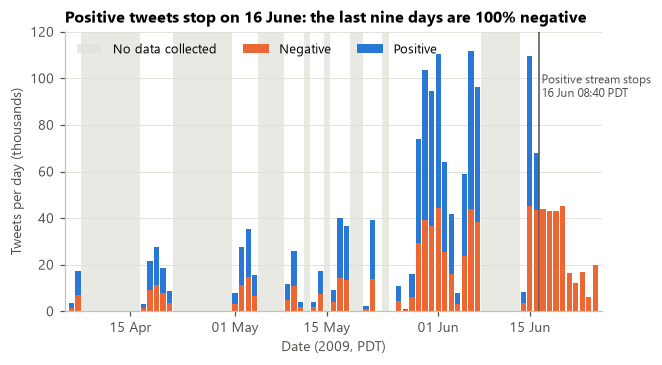

Last positive tweet: 2009-06-16 08:40:50. After it: 275,225 tweets, 100.0% negative.


In [7]:
# ------------------------------------------------------------------
# 3.1 Daily volume by label (Figure 2.1)
# ------------------------------------------------------------------
daily_lab = (raw.groupby([raw['dt'].dt.normalize(), 'label']).size()
                .unstack(fill_value=0).reindex(calendar, fill_value=0))
last_pos = raw.loc[raw['label'] == 'Positive', 'dt'].max()
after_cut = raw[raw['dt'] > last_pos]
keep('last_positive_ts', str(last_pos))
keep('n_after_cutoff', len(after_cut))
keep('neg_share_after_cutoff', (after_cut['label'] == 'Negative').mean())

fig, ax = plt.subplots(figsize=(6.3, 3.3))
x = daily_lab.index
# Light grey bands mark days on which nothing was collected
for i, d in enumerate(missing_days):
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=GRID, alpha=0.7, lw=0,
               zorder=0, label='No data collected' if i == 0 else None)
ax.bar(x, daily_lab['Negative'] / 1e3, width=0.8, color=NEG, label='Negative', zorder=2)
ax.bar(x, daily_lab['Positive'] / 1e3, width=0.8, bottom=daily_lab['Negative'] / 1e3,
       color=POS, label='Positive', zorder=2)
ax.axvline(last_pos, color=INK, lw=1, zorder=3)
ax.text(last_pos + pd.Timedelta(hours=10), 92, 'Positive stream stops\n16 Jun 08:40 PDT', fontsize=8, color=INK)
ax.set_title('Positive tweets stop on 16 June: the last nine days are 100% negative')
ax.set_xlabel('Date (2009, PDT)')
ax.set_ylabel('Tweets per day (thousands)')
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
ax.set_xlim(calendar.min() - pd.Timedelta(days=1), calendar.max() + pd.Timedelta(days=1))
ax.set_ylim(0, 120)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', ncols=3)
save_fig(fig, 'fig2_1_daily_volume_by_label')

print(f'Last positive tweet: {last_pos}. After it: {len(after_cut):,} tweets, '
      f"{pct((after_cut['label'] == 'Negative').mean())} negative.")

**Reading Figure 2.1.** Until the morning of 16 June both labels arrive every day in a similar ratio. After the last positive tweet (16 June, 08:40:50 PDT) the file still contains 275,225 tweets, and every one of them is negative. People did not suddenly become unhappy; the collector simply stopped searching for positive emoticons. If we kept these rows, any trend chart would show a fake collapse in sentiment and a time-based test set would contain a single class. The empty days are a second artifact: 33 of the 81 calendar days have no tweets at all, so raw daily counts measure the collector, not public interest.

In [8]:
# ------------------------------------------------------------------
# 3.2 Did the positive stream thin out before it stopped?
# ------------------------------------------------------------------
# If the last hours before the stop were already incomplete, we would cut earlier.
w = raw[(raw['dt'] >= '2009-06-16 04:00') & (raw['dt'] < '2009-06-16 10:00')]
hourly = w.groupby([w['dt'].dt.floor('h'), 'label']).size().unstack(fill_value=0)
hourly['Positive share'] = (hourly['Positive'] / hourly.sum(axis=1)).round(3)
hourly

label,Negative,Positive,Positive share
dt,,,
2009-06-16 04:00:00,1834,2809,0.605
2009-06-16 05:00:00,1971,2850,0.591
2009-06-16 06:00:00,1962,2861,0.593
2009-06-16 07:00:00,1948,2496,0.562
2009-06-16 08:00:00,1986,1911,0.490
2009-06-16 09:00:00,1911,0,0.000


The positive stream runs at its normal pace (about 2,800 tweets per hour) until 08:40 and then stops dead: the 08:00 hour holds 1,911 positive tweets in 41 minutes, which is the usual rate. So the right cut-off is the timestamp of the last positive tweet itself, and we keep both labels up to that second.

In [9]:
# ------------------------------------------------------------------
# 3.3 Conflicting labels and duplicated texts
# ------------------------------------------------------------------
CUTOFF = last_pos
dup_ids = raw.loc[raw['ids'].duplicated(keep=False)]
conflict_ids = dup_ids.groupby('ids')['label'].nunique().loc[lambda s: s > 1].index
keep('n_conflict_ids', len(conflict_ids))
keep('n_conflict_rows', int(raw['ids'].isin(conflict_ids).sum()))
print(f'{len(conflict_ids):,} tweet ids appear twice with BOTH labels '
      f"({raw['ids'].isin(conflict_ids).sum():,} rows). Example:")
display(raw.loc[raw['ids'] == conflict_ids[0], ['ids', 'label', 'text']])

top_dups = raw['text'].value_counts().head(8).rename('copies').to_frame()
keep('n_dup_text_rows', int(raw['text'].duplicated().sum()))
print(f"{raw['text'].duplicated().sum():,} rows repeat an earlier text exactly. Most repeated texts:")
top_dups

1,685 tweet ids appear twice with BOTH labels (3,370 rows). Example:


,ids,label,text
213,1467863684,Negative,Awwh babs... you look so sad underneith that shop entrance of &quot;Yesterday's Musik&quot; O-: I like th...
800261,1467863684,Positive,Awwh babs... you look so sad underneith that shop entrance of &quot;Yesterday's Musik&quot; O-: I like th...


18,534 rows repeat an earlier text exactly. Most repeated texts:


,copies
text,
isPlayer Has Died! Sorry,210
good morning,118
headache,115
Good morning,112
Headache,106
"cant afford to see Angels and Demons, so i watched it for free: http://tr.im/lvBu",86
"Not to worry, noone got that one. Next question starts in 1 minute, get your thinking caps on",86
Goodnight,85


## 4. Cleaning

**Goal:** build one analysis-ready table and document every row we remove (Chapter 1: "document all changes for transparency and reproducibility").
**Method:** five steps, each logged with the number of rows before and after:

1. drop tweet ids that carry both labels (the same tweet cannot be positive and negative);
2. keep only the period in which both labels were collected (up to 16 June 08:40:50);
3. normalise the text and drop tweets with no readable words;
4. drop normalised texts that occur with both labels;
5. keep the earliest copy of every normalised text (removes bots, spam and retweets of the same text).

Text normalisation keeps everything a sentiment model needs: negations, `!` and `?` stay; links and @usernames become the placeholder tokens `_url_` and `_user_`; letters repeated three or more times are shortened ("soooo" becomes "soo").

In [10]:
# ------------------------------------------------------------------
# 4.1 Text helpers
# ------------------------------------------------------------------
URL_RE = r'https?://\S+|www\.\S+'
_URL, _USER = re.compile(URL_RE), re.compile(r'@\w+')
_ELONG, _SPACE = re.compile(r'([a-z])\1{2,}'), re.compile(r'\s+')

def normalise_one(t: str) -> str:
    """Model-ready text: unescape HTML, placeholder tokens for links/users, lower case, shorten elongations."""
    t = html.unescape(t)                       # &quot; &amp; &lt; -> " & <
    t = _URL.sub(' _url_ ', t)
    t = _USER.sub(' _user_ ', t).lower()
    t = _ELONG.sub(r'\1\1', t)                 # "soooo" -> "soo"
    return _SPACE.sub(' ', t).strip()

def normalise(s: pd.Series) -> pd.Series:
    return s.map(normalise_one).astype(object)

# ------------------------------------------------------------------
# 4.2 Cleaning steps with a log
# ------------------------------------------------------------------
cleaning_log = [{'Step': '0. Raw file', 'Rows before': len(raw), 'Removed': 0, 'Rows after': len(raw),
                 'Reason': 'As downloaded from Kaggle'}]

def log_step(name, before, after, reason):
    cleaning_log.append({'Step': name, 'Rows before': before, 'Removed': before - after,
                         'Rows after': after, 'Reason': reason})

df = raw.drop(columns=['date', 'flag', 'target'])

n = len(df); df = df[~df['ids'].isin(conflict_ids)]
log_step('1. Consistent labels', n, len(df), 'Same tweet id labelled both positive and negative')

n = len(df); df = df[df['dt'] <= CUTOFF]
log_step('2. Collection window', n, len(df), 'After 16 Jun 08:40:50 only negative tweets were collected')

n = len(df)
df['text_norm'] = normalise(df['text'])
df = df[df['text_norm'].str.replace(r'_url_|_user_', '', regex=True).str.contains(r'[a-z]', regex=True)]
log_step('3. Readable text', n, len(df), 'No words left after removing links and @usernames')

n = len(df)
both = df.groupby('text_norm')['label'].nunique()
df = df[~df['text_norm'].isin(both[both > 1].index)]
log_step('4. Unambiguous text', n, len(df), 'Identical normalised text appears with both labels')

n = len(df)
df = df.sort_values(['dt', 'ids']).drop_duplicates('text_norm', keep='first')
log_step('5. Unique texts', n, len(df), 'Later copies of the same text (bots, spam, repeated posts)')

log_df = pd.DataFrame(cleaning_log)
log_df['% of raw kept'] = (log_df['Rows after'] / len(raw) * 100).round(1)
keep('n_clean', len(df))
keep('pos_share_clean', (df['label'] == 'Positive').mean())
log_df

,Step,Rows before,Removed,Rows after,Reason,% of raw kept
0,0. Raw file,1600000,0,1600000,As downloaded from Kaggle,100.0
1,1. Consistent labels,1600000,3370,1596630,Same tweet id labelled both positive and negative,99.8
2,2. Collection window,1596630,275225,1321405,After 16 Jun 08:40:50 only negative tweets were collected,82.6
3,3. Readable text,1321405,3179,1318226,No words left after removing links and @usernames,82.4
4,4. Unambiguous text,1318226,14139,1304087,Identical normalised text appears with both labels,81.5
5,5. Unique texts,1304087,30053,1274034,"Later copies of the same text (bots, spam, repeated posts)",79.6


In [11]:
# ------------------------------------------------------------------
# 4.3 Features used later (all derived from the text or the timestamp)
# ------------------------------------------------------------------
df['text_disp'] = df['text'].map(html.unescape).str.strip()        # readable text for tables and the dashboard
df['neg'] = (df['label'] == 'Negative').astype('int8')
df['n_words'] = df['text_disp'].str.split().str.len().astype('int16')
df['n_chars'] = df['text_disp'].str.len().astype('int16')
df['has_url'] = df['text'].str.contains(URL_RE, regex=True)
df['has_mention'] = df['text'].str.contains(r'@\w+', regex=True)
df['has_hashtag'] = df['text'].str.contains(r'#\w+', regex=True)
df['n_exclaim'] = df['text'].str.count('!').astype('int16')
df['date'] = df['dt'].dt.normalize()
df['hour'] = df['dt'].dt.hour.astype('int8')
df['weekday'] = df['dt'].dt.day_name()
df['weekend'] = df['dt'].dt.dayofweek >= 5
DAYPARTS = ['Night (0-5h)', 'Morning (6-11h)', 'Afternoon (12-17h)', 'Evening (18-23h)']
df['daypart'] = pd.cut(df['hour'], [-1, 5, 11, 17, 23], labels=DAYPARTS)

# Time periods used for the story and for the time-based train/validation/test split
LAUNCH_START, LAUNCH_END, TEST_START = pd.Timestamp('2009-06-01'), pd.Timestamp('2009-06-08'), pd.Timestamp('2009-06-14')
PERIODS = ['Baseline', 'Launch week', 'Next week']
df['period'] = np.select([df['dt'] < LAUNCH_START, df['dt'] < LAUNCH_END, df['dt'] >= TEST_START],
                         PERIODS, default='Gap')
print(df['period'].value_counts().reindex(PERIODS + ['Gap']).fillna(0).astype(int).to_string())
df = df.reset_index(drop=True)
df[['dt', 'label', 'text_norm', 'n_words', 'has_url', 'has_mention', 'daypart', 'period']].head(4)

period
Baseline       653345
Launch week    469953
Next week      150736
Gap                 0


,dt,label,text_norm,n_words,has_url,has_mention,daypart,period
0,2009-04-06 22:19:45,Negative,"_user_ _url_ - aww, that's a bummer. you shoulda got david carr of third day to do it. ;d",19,True,True,Evening (18-23h),Baseline
1,2009-04-06 22:19:49,Negative,is upset that he can't update his facebook by texting it... and might cry as a result school today also. b...,21,False,False,Evening (18-23h),Baseline
2,2009-04-06 22:19:53,Negative,_user_ i dived many times for the ball. managed to save 50% the rest go out of bounds,18,False,True,Evening (18-23h),Baseline
3,2009-04-06 22:19:57,Negative,my whole body feels itchy and like its on fire,10,False,False,Evening (18-23h),Baseline


**Result.** About 1.28 million tweets survive cleaning (exact figures in the log above). The biggest cut is step 2, the negative-only tail, which on its own removes about 17% of the file. After cleaning, roughly 60% of the remaining tweets are positive. As explained in Section 1, that ratio comes from the collection process, which is why later sections compare groups with each other instead of reading the 60% as "how happy Twitter was".

## 5. Building the F&B conversation stream

**Goal:** separate the tweets that talk about food and drink, because they stand in for the conversation around our brand.
**Method:** a hand-written dictionary of regular expressions with word boundaries, organised in six categories plus a brand list. Ambiguous words are handled with explicit rules (e.g. *Subway* only counts when the tweet also mentions food, *Sonic* only with "drive-in"-type words, "tea party" and "Jimmy Eat World" are removed before matching). We match on the lower-cased text with links removed but @handles kept, so a tweet addressed to `@starbucks` counts as a Starbucks mention.
**What to look for:** how many tweets are captured, and whether the captured tweets really are about food (checked by a manual review of a random sample in 5.4).

In [12]:
# ------------------------------------------------------------------
# 5.1 Dictionaries: brands, categories, aspects
# ------------------------------------------------------------------
FOOD_CONTEXT = r'(?:sandwich|sub|subs|footlong|lunch|dinner|breakfast|eat|ate|eating|hungry|food|meal|cookie|cookies)'
BRANDS = {
    'Starbucks': r'\bstarbucks?\b|\bsbux\b',
    "McDonald's": r"\bmc ?donald'?s?\b|\bmcd'?s\b|\bmickey d'?s\b",
    'Coca-Cola': r'\bcoca[- ]?cola\b|\b(?:diet )?coke(?: zero)?\b',
    'Pepsi': r'\bpepsi\b',
    'Taco Bell': r'\btaco ?bell\b',
    'KFC': r'\bkfc\b',
    'Subway': rf'\bsubway\b(?=.*\b{FOOD_CONTEXT}\b)|\b{FOOD_CONTEXT}\b.*\bsubway\b',
    'Chipotle': r'\bchipotle\b',
    "Dunkin'": r"\bdunkin'?\b",
    'Krispy Kreme': r'\bkrispy ?kreme\b',
    'Burger King': r'\bburger ?king\b',
    'Pizza Hut': r'\bpizza ?hut\b',
    "Domino's": r"\bdomino'?s\b(?! effect)",
    "Wendy's": r"\bwendys\b|\bwendy's\b(?! (?:house|place|party|mom|room|birthday))",
    'In-N-Out': r'\bin[- ]?n[- ]?out\b',
    'Sonic': r'\bsonic\b(?=.*\b(?:drive|slush|slushes|tots|limeade|happy hour)\b)',
    'Red Bull': r'\bred ?bull\b',
    'Oreo': r'\boreos?\b',
    'Jamba Juice': r'\bjamba\b',
    'Pinkberry': r'\bpinkberry\b',
    'Chick-fil-A': r'\bchick[- ]?fil[- ]?a\b',
    'Panera': r'\bpanera\b',
    'Dr Pepper': r'\bdr\.? ?pepper\b',
    'Mountain Dew': r'\bmountain dew\b|\bmtn dew\b',
    'Cold Stone': r'\bcold ?stone\b',
    "Ben & Jerry's": r"\bben (?:and|&) jerry'?s?\b",
    'IHOP': r'\bihop\b',
    "Denny's": r"\bdenny'?s\b",
    "Arby's": r"\barby'?s\b",
    'Popeyes': r'\bpopeyes\b',
    'Olive Garden': r'\bolive garden\b',
    "Applebee's": r"\bapplebee'?s\b",
    'Jack in the Box': r'\bjack in the box\b',
    'White Castle': r'\bwhite castle\b',
    'Five Guys': r'\bfive guys\b',
    "Papa John's": r"\bpapa john'?s\b",
    'Cheesecake Factory': r'\bcheesecake factory\b',
    'Snickers': r'\bsnickers\b',
    'Skittles': r'\bskittles\b',
    'Nutella': r'\bnutella\b',
    'Gatorade': r'\bgatorade\b',
}

CATEGORIES = {
    'Coffee & tea': r'\b(?:coffees?|caffeine|espressos?|lattes?|cappuccinos?|frappuccinos?|frapp?es?|mochas?|'
                    r'macchiatos?|americanos?|teas?|chai|boba|bubble tea)\b',
    'Sweets & desserts': r'\b(?:ice ?creams?|chocolates?|cakes?|cupcakes?|cookies?|cand(?:y|ies)|desserts?|donuts?|'
                         r'doughnuts?|froyo|frozen yogh?urt|brownies?|muffins?|pies?|sweets|pastr(?:y|ies)|gelato|'
                         r'sundaes?|popsicles?|nutella|oreos?)\b',
    'Drinks': r'\b(?:sodas?|cokes?|pepsi|juices?|smoothies?|milkshakes?|milk shakes?|lemonade|beers?|wines?|'
              r'cocktails?|margaritas?|vodka|tequila|mojitos?|slurpees?|energy drinks?|red bull|gatorade|'
              r'drinks?|drinking|drank)\b',
    'Dishes': r'\b(?:pizzas?|burgers?|cheeseburgers?|hamburgers?|fries|sandwich(?:es)?|chicken|sushi|pasta|spaghetti|'
              r'salads?|steaks?|tacos?|burritos?|nachos|noodles|ramen|cereal|pancakes?|waffles?|bacon|eggs|cheese|'
              r'soup|bbq|barbecue|hot ?dogs?|chicken wings|hot wings|bagels?|rice|curry|pho|dumplings?|seafood|'
              r'shrimp|lobster|ribs|lasagna|mac (?:and|n|&) cheese|grilled cheese|fish (?:and|n|&) chips)\b',
    'Meals & hunger': r'\b(?:breakfast|brunch|lunch|dinner|supper|meals?|snacks?|snacking|foods?|hungry|starving|'
                      r'starved|famished|craving|cravings|crave|munchies|restaurants?|menu|cafe|diner|takeout|'
                      r'take-out|eat|eats|eating|ate|cooking|cooked|baking)\b',
}
# Phrases removed before matching because they contain a food word but are not about food
NOT_FOOD = r"jimmy eat world|tea ?party|tea ?parties|teabag\w*|piece of cake|eye candy|say cheese|pie chart|" \
           r"cheesy|big cheese|walking dead|eat my shorts|cutie ?pie|sweetie ?pie|honey ?pie|american pie"

# Aspects: what about the experience is the tweet discussing? (sentiment words are deliberately excluded)
ASPECTS = {
    'Taste & quality': r'\b(?:tastes?|tasted|tasting|flavou?rs?|recipes?|ingredients?|quality|texture|fresh|stale|'
                       r'spicy|crispy|crunchy|soggy|burnt|greasy|salty|undercooked|overcooked|homemade|portions?)\b',
    'Price & value': r'\b(?:prices?|pricey|expensive|cheap|cheaper|costs?|costly|dollars?|bucks|money|paid|pay|'
                     r'paying|deals?|coupons?|discount|on sale|for free|afford|budget|value meal|free (?:coffee|food|'
                     r'drinks?|lunch|dinner|breakfast|ice cream|samples?|refills?|cone|donuts?|pancakes?))\b|\$\s?\d',
    'Service & wait': r'\b(?:service|waiters?|waitress(?:es)?|staff|cashiers?|baristas?|managers?|employees?|rude|'
                      r'in line|long line|the line|queue|waited|waiting|wait|slow|drive[- ]?thru|drive[- ]?through|'
                      r'ordered|order|orders|ordering|delivery|delivered|deliver|took forever|counter|reservations?)\b',
    'Availability': r"\b(?:sold out|ran out|run out|runs out|running out|out of stock|closed|closes|closing|shut down|"
                    r"no more|none left|all gone|discontinued|unavailable|not available|couldn'?t find|"
                    r"could not find|can'?t find|cannot find|back in stock|limited time|only available)\b",
    'Novelty & trial': r"\bnew\b|\b(?:tried|try|trying) (?:the|a|an|some|this|that|their|out|it)\b|\bfirst time\b|"
                       r"\bnever (?:had|tried)\b|\blimited edition\b|\bseasonal\b|\blaunch(?:ed|es)?\b",
    'Hunger & cravings': r"\b(?:hungry|starving|starved|famished|craving|cravings|crave|craves|munchies|"
                         r"haven'?t eaten|need food|empty stomach)\b",
    'Health & diet': r'\b(?:diet|dieting|calories|calorie|healthy|unhealthy|health|fat|fattening|gym|workout|'
                     r'work out|weight|sugar|vegan|vegetarian|sick|stomach|tummy|nausea|food poisoning|'
                     r'allerg(?:y|ic)|junk food|carbs)\b',
    'Social occasions': r'\b(?:friends?|family|mom|mum|dad|parents|sister|brother|boyfriend|girlfriend|bf|gf|'
                        r'husband|wife|date|party|bbq|barbecue|picnic|birthday|celebrat\w*)\b',
}
CAFFEINE = r'\b(?:coffees?|caffeine|espressos?|lattes?|cappuccinos?|teas?|red bull|energy drinks?)\b'
MORNING = r"\b(?:morning|mornings|wake|woke|waking|awake|tired|sleepy|exhausted|monday|first cup|" \
          r"need (?:my|a|some|more) (?:coffee|caffeine|tea))\b"
NOT_WAIT = r"can'?t wait|cannot wait|can not wait|wait and see|wait for it|in order to"
PRODUCT_ASPECTS = ['Taste & quality', 'Price & value', 'Service & wait', 'Availability', 'Novelty & trial']
CONTEXT_ASPECTS = ['Hunger & cravings', 'Health & diet', 'Morning caffeine', 'Social occasions']
ASPECT_ORDER = PRODUCT_ASPECTS + CONTEXT_ASPECTS
ASPECT_GROUP = {a: ('Product-directed' if a in PRODUCT_ASPECTS else 'Context') for a in ASPECT_ORDER}

In [13]:
# ------------------------------------------------------------------
# 5.2 Tag every clean tweet
# ------------------------------------------------------------------
t0 = time.time()
# Lower-cased text without links; @handles are kept so "@starbucks" counts as a brand mention
low = df['text_disp'].str.replace(URL_RE, ' ', regex=True).str.lower()
low_food = low.str.replace(NOT_FOOD, ' ', regex=True)

brand_hits = pd.DataFrame({b: low_food.str.contains(p, regex=True) for b, p in BRANDS.items()})
cat_hits = pd.DataFrame({c: low_food.str.contains(p, regex=True) for c, p in CATEGORIES.items()})
cat_hits['Chains & brands'] = brand_hits.any(axis=1)
df['is_fnb'] = cat_hits.any(axis=1)

# Primary category = the most specific category that matched (brands first, generic meal words last)
PRIORITY = ['Chains & brands', 'Coffee & tea', 'Sweets & desserts', 'Drinks', 'Dishes', 'Meals & hunger']
df['category'] = np.select([cat_hits[c] for c in PRIORITY], PRIORITY, default='')
df['brands'] = [', '.join(brand_hits.columns[row]) for row in brand_hits.to_numpy()]
print(f'Tagging took {time.time() - t0:.0f}s')

# Aspects are only computed for F&B tweets
fnb = df[df['is_fnb']].copy()
f_low = low_food[df['is_fnb']]
for a, p in ASPECTS.items():
    src = f_low.str.replace(NOT_WAIT, ' ', regex=True) if a == 'Service & wait' else f_low
    fnb[a] = src.str.contains(p, regex=True)
fnb['Morning caffeine'] = f_low.str.contains(CAFFEINE, regex=True) & f_low.str.contains(MORNING, regex=True)
fnb['n_aspects'] = fnb[ASPECT_ORDER].sum(axis=1)
fnb['any_product_aspect'] = fnb[PRODUCT_ASPECTS].any(axis=1)

keep('n_fnb', len(fnb)); keep('fnb_share_of_clean', len(fnb) / len(df))
keep('n_fnb_users', fnb['user'].nunique())
keep('n_brand_mentions', int((fnb['brands'] != '').sum()))
print(f"F&B stream: {len(fnb):,} tweets ({pct(len(fnb) / len(df))} of the clean corpus) "
      f"from {fnb['user'].nunique():,} users; {(fnb['brands'] != '').sum():,} mention a named brand.")
pd.DataFrame({'Tweets matching (multi-label)': cat_hits[df['is_fnb']].sum(),
              'Primary category': fnb['category'].value_counts()}).reindex(CAT_ORDER)

Tagging took 98s


F&B stream: 84,632 tweets (6.6% of the clean corpus) from 69,033 users; 6,353 mention a named brand.


,Tweets matching (multi-label),Primary category
Meals & hunger,40885,31456
Coffee & tea,9365,8932
Sweets & desserts,12500,11387
Dishes,17563,15251
Drinks,13763,11253
Chains & brands,6353,6353


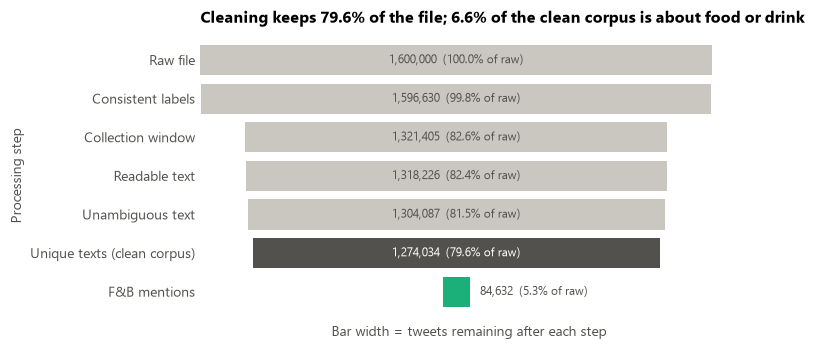

In [14]:
# ------------------------------------------------------------------
# 5.3 Funnel: from the raw file to the analysis-ready F&B stream (Figure 2.2)
# ------------------------------------------------------------------
stages = log_df[['Step', 'Rows after']].copy()
stages.loc[len(stages)] = ['6. F&B mentions', len(fnb)]
stages['label'] = ['Raw file', 'Consistent labels', 'Collection window', 'Readable text',
                   'Unambiguous text', 'Unique texts (clean corpus)', 'F&B mentions']

fig, ax = plt.subplots(figsize=(6.3, 3.4))
top = stages['Rows after'].max()
colors = [LIGHT] * 5 + [INK, AQUA]
ys = np.arange(len(stages))[::-1]
for y, v, c in zip(ys, stages['Rows after'], colors):
    ax.barh(y, v, left=(top - v) / 2, color=c, height=0.78, zorder=2)
    text = f'{v:,}  ({v / top:.1%} of raw)'
    if v > 0.3 * top:      # label inside wide bars, beside narrow ones
        ax.text(top / 2, y, text, ha='center', va='center', fontsize=8, zorder=3,
                color='white' if c == INK else INK)
    else:
        ax.text((top + v) / 2 + top * 0.02, y, text, ha='left', va='center', fontsize=8, color=INK)
ax.set_yticks(ys, stages['label'])
ax.set_xticks([])
ax.grid(False)
ax.spines[['left', 'bottom']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_xlabel('Bar width = tweets remaining after each step')
ax.set_ylabel('Processing step')
ax.set_title(f"Cleaning keeps {len(df) / len(raw):.1%} of the file; "
             f"{len(fnb) / len(df):.1%} of the clean corpus is about food or drink")
save_fig(fig, 'fig2_2_cleaning_funnel')

**Reading Figure 2.2.** Cleaning removes 325,966 rows (20.4% of the file), and 84% of them are the negative-only tail. Dropping ambiguous and repeated texts costs another 2.8% but takes out bots such as the 210 copies of "isPlayer Has Died! Sorry". The F&B stream used in Sections 6 to 8 holds 84,632 tweets, 6.6% of the clean corpus.

### 5.4 Checking the dictionary by reading a sample

A keyword filter is only useful if what it catches is really about food. We drew a stratified random sample of 210 F&B tweets (35 per primary category) and read every one of them, recording two things: whether the tweet is genuinely about food or drink (`is_fnb_review`), and the sentiment a human reader would give it (`review_sentiment`: Positive, Negative or Neutral). **Disclosure:** the review was done with AI assistance by a single reviewer, so there is no inter-rater agreement figure; we report it as a spot-check, not as a gold standard.

In [15]:
# ------------------------------------------------------------------
# 5.4 Stratified review sample (35 tweets per primary category)
# ------------------------------------------------------------------
sample_path = DIRS['val'] / 'fnb_validation_sample.xlsx'
reviewed_path = DIRS['val'] / 'fnb_validation_sample_reviewed.xlsx'

sample = (fnb.groupby('category').sample(n=35, random_state=SEED)
             .sort_values(['category', 'dt']).reset_index(drop=True))
sample = sample[['ids', 'category', 'brands', 'label', 'text_disp']].rename(
    columns={'label': 'emoticon_label', 'text_disp': 'text'})
sample.insert(0, 'sample_id', range(1, len(sample) + 1))
sample['is_fnb_review'] = ''          # 1 = about food/drink, 0 = not
sample['review_sentiment'] = ''       # Positive / Negative / Neutral
sample['note'] = ''
if not sample_path.exists():
    sample.to_excel(sample_path, index=False)

if reviewed_path.exists():
    rev = pd.read_excel(reviewed_path)
    k, n = int(rev['is_fnb_review'].sum()), len(rev)
    p, lo, hi = prop_ci(k, n)
    keep('lexicon_precision', p); keep('lexicon_precision_lo', lo); keep('lexicon_precision_hi', hi)
    by_cat = rev.groupby('category')['is_fnb_review'].agg(['sum', 'count'])
    by_cat['precision'] = (by_cat['sum'] / by_cat['count']).round(3)
    # Agreement between the emoticon label and the reader, on tweets the reader did not call neutral
    on_topic = rev[(rev['is_fnb_review'] == 1)]
    polar = on_topic[on_topic['review_sentiment'].isin(['Positive', 'Negative'])]
    agree = (polar['review_sentiment'] == polar['emoticon_label']).mean()
    keep('review_neutral_share', (on_topic['review_sentiment'] == 'Neutral').mean())
    keep('review_label_agreement', agree)
    print(f'Dictionary precision: {k}/{n} = {p:.1%} (95% CI {lo:.1%} to {hi:.1%})')
    print(f"Reader called {pct((on_topic['review_sentiment'] == 'Neutral').mean())} of on-topic tweets neutral; "
          f'on the rest the emoticon label agrees with the reader {agree:.1%} of the time.')
    display(by_cat.reindex(CAT_ORDER))
else:
    print(f'Review file not found yet: fill in {sample_path.name} and save it as {reviewed_path.name}')

Dictionary precision: 187/210 = 89.0% (95% CI 84.8% to 93.3%)
Reader called 15.0% of on-topic tweets neutral; on the rest the emoticon label agrees with the reader 96.9% of the time.


,sum,count,precision
category,,,
Meals & hunger,30,35,0.857
Coffee & tea,32,35,0.914
Sweets & desserts,29,35,0.829
Dishes,29,35,0.829
Drinks,33,35,0.943
Chains & brands,34,35,0.971


**Result of the review.** 187 of the 210 sampled tweets are really about food or drink, a precision of 89.0% (95% CI 84.8% to 93.3%). Most misses are figurative uses: pet names ("my cupcake", "love muffin"), idioms ("I'll drink to that", "starving artist") and meal words used only as a time reference ("signing off until lunch"). Brand and drink tweets are the cleanest (97% and 94%), sweets and dishes the noisiest (83%). On tweets with a clear sentiment, the emoticon label agrees with the reader 96.9% of the time, and 15% of on-topic tweets read as neutral, a reminder that the dataset has no neutral class.

## 6. Descriptive analysis: what happened?

**Goal:** summarise the F&B conversation with counts, percentages and distributions (Chapter 1: descriptive analytics answers "What happened? How many?").
**Method:** summary tables by period, then five charts, each chosen for the job it does (Chapter 2): a donut for part-to-whole, a Pareto chart for "which few brands matter", a histogram for a distribution, a line chart for change over time, and a bar chart to compare categories.
**What to look for:** where the conversation is concentrated, and how the F&B negative share compares with all tweets collected on the same days.

In [16]:
# ------------------------------------------------------------------
# 6.1 Summary by period: all tweets vs the F&B stream
# ------------------------------------------------------------------
def summarise(d):
    return pd.Series({'Tweets': len(d), 'Negative share': d['neg'].mean()})

rows = []
for per in PERIODS + ['All periods']:
    a = df if per == 'All periods' else df[df['period'] == per]
    f = fnb if per == 'All periods' else fnb[fnb['period'] == per]
    rows.append({'Period': per, 'All tweets': len(a), 'F&B tweets': len(f),
                 'F&B % of all': len(f) / len(a), 'Negative share, all': a['neg'].mean(),
                 'Negative share, F&B': f['neg'].mean(),
                 'Lift (pp)': 100 * (f['neg'].mean() - a['neg'].mean())})
period_tbl = pd.DataFrame(rows).set_index('Period')
for per in period_tbl.index:
    tag = per.lower().replace(' ', '_')
    keep(f'neg_all_{tag}', period_tbl.loc[per, 'Negative share, all'])
    keep(f'neg_fnb_{tag}', period_tbl.loc[per, 'Negative share, F&B'])
    keep(f'lift_{tag}', period_tbl.loc[per, 'Lift (pp)'], 2)
    keep(f'n_fnb_{tag}', period_tbl.loc[per, 'F&B tweets'])
period_tbl.style.format({'All tweets': '{:,}', 'F&B tweets': '{:,}', 'F&B % of all': '{:.1%}',
                         'Negative share, all': '{:.1%}', 'Negative share, F&B': '{:.1%}', 'Lift (pp)': '{:+.1f}'})

,All tweets,F&B tweets,F&B % of all,"Negative share, all","Negative share, F&B",Lift (pp)
Period,,,,,,
Baseline,"653,345","44,184",6.8%,39.6%,34.5%,-5.1
Launch week,"469,953","30,921",6.6%,39.9%,34.5%,-5.4
Next week,"150,736","9,527",6.3%,40.9%,36.8%,-4.2
All periods,"1,274,034","84,632",6.6%,39.9%,34.8%,-5.1


**Reading the table.** About one tweet in fifteen (6.6%) is about food or drink, and the share is stable across periods (6.3% to 6.8%). F&B tweets are 34.8% negative against 39.9% for all tweets, a lift of -5.1 pp. The lift in launch week (-5.4 pp) is almost the same as in the baseline weeks (-5.1 pp) and narrows to -4.2 pp in the next week. The raw counts (44,184 / 30,921 / 9,527 F&B tweets) mostly reflect how long the collector ran, so we compare shares, not counts.

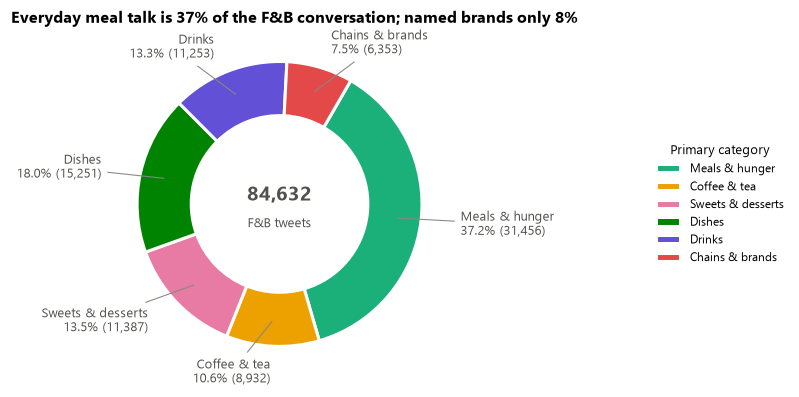

In [17]:
# ------------------------------------------------------------------
# 6.2 Share of voice by primary category (Figure 3.1, donut)
# ------------------------------------------------------------------
share = fnb['category'].value_counts().reindex(CAT_ORDER)
for c in CAT_ORDER:
    keep(f"share_{c.split(' ')[0].lower()}", share[c] / len(fnb))

fig, ax = plt.subplots(figsize=(6.3, 3.7))
wedges, _ = ax.pie(share, colors=[CAT_COLORS[c] for c in CAT_ORDER], startangle=60, counterclock=False,
                   wedgeprops=dict(width=0.38, edgecolor='white', linewidth=2))
for w, c in zip(wedges, CAT_ORDER):          # direct labels: name, share and count
    ang = np.deg2rad((w.theta2 + w.theta1) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax.annotate(f'{c}\n{share[c] / len(fnb):.1%} ({share[c]:,})', xy=(0.81 * x, 0.81 * y),
                xytext=(1.28 * x, 1.18 * y), ha='left' if x > 0 else 'right', va='center', fontsize=8.5,
                color=INK, arrowprops=dict(arrowstyle='-', color=GRAY, lw=0.7))
ax.text(0, 0.06, f'{len(fnb):,}', ha='center', va='center', fontsize=13, fontweight='bold', color=INK)
ax.text(0, -0.14, 'F&B tweets', ha='center', va='center', fontsize=8.5, color=INK)
ax.set_title(f'Everyday meal talk is {share.iloc[0] / len(fnb):.0%} of the F&B conversation; '
             f'named brands only {share["Chains & brands"] / len(fnb):.0%}', pad=16)
ax.axis('equal')
ax.legend(wedges, CAT_ORDER, loc='center left', bbox_to_anchor=(1.18, 0.5), title='Primary category',
          fontsize=8, title_fontsize=8.5)
save_fig(fig, 'fig3_1_share_of_voice_donut')

**Reading Figure 3.1.** More than a third of the F&B conversation (37.2%) is everyday meal talk such as "lunch", "dinner" or "so hungry", while only 7.5% names a chain or a brand. A brand that listens only for its own name would miss most of the category conversation in which its product is actually discussed.

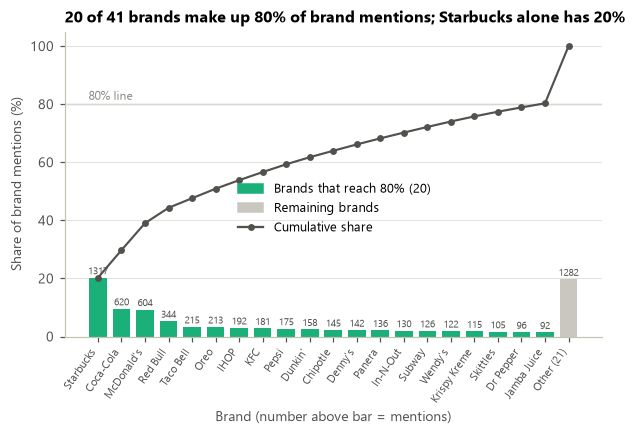

In [18]:
# ------------------------------------------------------------------
# 6.3 Which brands carry the brand conversation? (Figure 3.2, Pareto)
# ------------------------------------------------------------------
brand_long = fnb.loc[fnb['brands'] != '', ['brands', 'neg']].assign(brand=lambda d: d['brands'].str.split(', ')).explode('brand')
brand_stats = brand_long.groupby('brand').agg(mentions=('neg', 'size'), neg_share=('neg', 'mean')).sort_values('mentions', ascending=False)
brand_stats['share'] = brand_stats['mentions'] / brand_stats['mentions'].sum()
brand_stats['cum_share'] = brand_stats['share'].cumsum()
n_vital = int((brand_stats['cum_share'] < 0.80).sum() + 1)          # brands needed to reach 80%
keep('n_brands_found', len(brand_stats)); keep('n_brands_80pct', n_vital)
keep('starbucks_share_of_brand_mentions', brand_stats.loc['Starbucks', 'share'])

TOP = n_vital          # show every brand needed to reach 80%, fold the rest into 'Other'
top = brand_stats.head(TOP).copy()
other = brand_stats.iloc[TOP:]
top.loc[f'Other ({len(other)})'] = [other['mentions'].sum(), np.nan, other['share'].sum(), 1.0]

fig, ax = plt.subplots(figsize=(6.3, 3.6))
xs = np.arange(len(top))
bar_colors = [AQUA if i < n_vital else LIGHT for i in range(len(top))]
ax.bar(xs, top['share'] * 100, color=bar_colors, width=0.75, zorder=2)
ax.plot(xs, top['cum_share'] * 100, color=INK, marker='o', ms=3.5, lw=1.4, zorder=3, label='Cumulative share')
ax.axhline(80, color=GRAY, lw=0.8, zorder=1)
ax.text(-0.4, 81.5, '80% line', ha='left', fontsize=8, color=GRAY)
for x, (m, s) in zip(xs, zip(top['mentions'], top['share'])):
    ax.text(x, s * 100 + 1.2, f'{int(m)}', ha='center', fontsize=6.5, color=INK)
ax.set_xticks(xs, top.index, rotation=55, ha='right', fontsize=7.5)
ax.set_ylabel('Share of brand mentions (%)')
ax.set_xlabel('Brand (number above bar = mentions)')
ax.set_ylim(0, 105)
ax.grid(axis='x', visible=False)
ax.legend(handles=[Patch(color=AQUA, label=f'Brands that reach 80% ({n_vital})'), Patch(color=LIGHT, label='Remaining brands'),
                   mpl.lines.Line2D([], [], color=INK, marker='o', ms=3.5, label='Cumulative share')],
          loc='center left', bbox_to_anchor=(0.30, 0.42))
ax.set_title(f'{n_vital} of {len(brand_stats)} brands make up 80% of brand mentions; '
             f'Starbucks alone has {brand_stats.loc["Starbucks", "share"]:.0%}')
save_fig(fig, 'fig3_2_brand_pareto')

**Reading Figure 3.2.** Brand mentions have a long tail: 20 of the 41 brands in our list make up 80% of them, and Starbucks alone has 20% (1,317 mentions), ahead of Coca-Cola (620) and McDonald's (604). Krispy Kreme (55% negative) and Wendy's (52%) are the most negative brands with more than 100 mentions, although these samples are small.

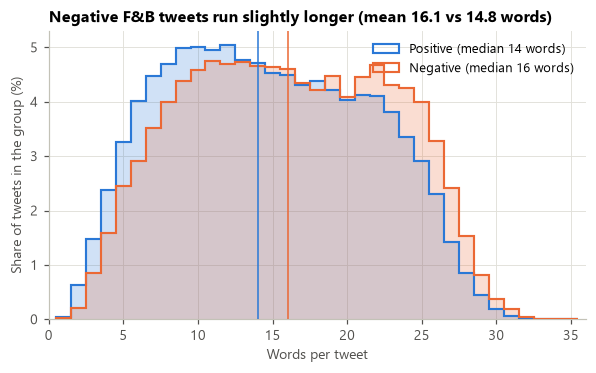

Welch t' = 27.3, p = 1.7e-163, Cohen's d = 0.20


,Tweets,Mean words,Median words,SD,Skewness
label,,,,,
Negative,29430,16.08,16.0,6.71,0.02
Positive,55202,14.76,14.0,6.63,0.13


In [19]:
# ------------------------------------------------------------------
# 6.4 Tweet length by sentiment (Figure 3.3, histogram) + summary statistics
# ------------------------------------------------------------------
len_stats = fnb.groupby('label')['n_words'].agg(['count', 'mean', 'median', 'std', lambda s: stats.skew(s)])
len_stats.columns = ['Tweets', 'Mean words', 'Median words', 'SD', 'Skewness']
neg_len, pos_len = fnb.loc[fnb['neg'] == 1, 'n_words'], fnb.loc[fnb['neg'] == 0, 'n_words']
welch = stats.ttest_ind(neg_len, pos_len, equal_var=False)         # Welch t' test (Chapter 5)
pooled_sd = np.sqrt((neg_len.var() + pos_len.var()) / 2)
d_len = (neg_len.mean() - pos_len.mean()) / pooled_sd                # Cohen's d (effect size)
keep('len_mean_neg', neg_len.mean(), 2); keep('len_mean_pos', pos_len.mean(), 2)
keep('len_median_neg', neg_len.median()); keep('len_median_pos', pos_len.median())
keep('len_welch_t', welch.statistic, 2); keep('len_cohens_d', d_len, 3)
keep('len_skew_neg', stats.skew(neg_len), 3); keep('len_skew_pos', stats.skew(pos_len), 3)

fig, ax = plt.subplots(figsize=(6.3, 3.4))
bins = np.arange(0.5, 36.5, 1)
for lab in ['Positive', 'Negative']:
    v = fnb.loc[fnb['label'] == lab, 'n_words']
    ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), histtype='stepfilled', alpha=0.22,
            color=SENT_COLORS[lab], zorder=2)
    ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), histtype='step', lw=1.4,
            color=SENT_COLORS[lab], zorder=3, label=f'{lab} (median {v.median():.0f} words)')
    ax.axvline(v.median(), color=SENT_COLORS[lab], lw=1, zorder=4)
ax.set_xlabel('Words per tweet')
ax.set_ylabel('Share of tweets in the group (%)')
ax.set_xlim(0, 36)
ax.legend(loc='upper right')
ax.set_title(f'Negative F&B tweets run slightly longer (mean {neg_len.mean():.1f} vs {pos_len.mean():.1f} words)')
save_fig(fig, 'fig3_3_length_histogram')
print(f"Welch t' = {welch.statistic:.1f}, p = {welch.pvalue:.2g}, Cohen's d = {d_len:.2f}")
len_stats.round(2)

**Reading Figure 3.3.** Both distributions are close to symmetric (skewness 0.02 and 0.13) and are capped by the 140-character limit. Negative tweets are about 1.3 words longer on average (16.1 vs 14.8). With 84,632 tweets the Welch test is highly significant (t' = 27.3), yet Cohen's d is only 0.20, a small effect: people explain a bad experience slightly more than a good one.

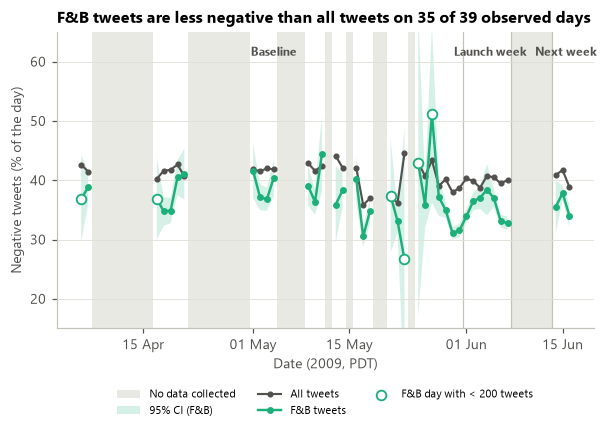

In [20]:
# ------------------------------------------------------------------
# 6.5 Daily negative share: F&B vs all tweets (Figure 3.4, line chart with 95% CI)
# ------------------------------------------------------------------
cal = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
day_all = df.groupby('date')['neg'].agg(['size', 'mean']).reindex(cal)        # missing days stay NaN -> line breaks
day_fnb = fnb.groupby('date')['neg'].agg(['size', 'sum', 'mean']).reindex(cal)
se = np.sqrt(day_fnb['mean'] * (1 - day_fnb['mean']) / day_fnb['size'])
day_fnb['lo'], day_fnb['hi'] = day_fnb['mean'] - 1.96 * se, day_fnb['mean'] + 1.96 * se
daily = pd.DataFrame({'n_all': day_all['size'], 'neg_all': day_all['mean'], 'n_fnb': day_fnb['size'],
                      'neg_fnb': day_fnb['mean'], 'lo': day_fnb['lo'], 'hi': day_fnb['hi']})
daily['lift_pp'] = 100 * (daily['neg_fnb'] - daily['neg_all'])
obs = daily.dropna(subset=['neg_fnb'])
keep('days_fnb_below_all', int((obs['neg_fnb'] < obs['neg_all']).sum())); keep('days_observed', len(obs))
keep('daily_lift_mean', obs['lift_pp'].mean(), 2); keep('daily_lift_min', obs['lift_pp'].min(), 2)
keep('daily_lift_max', obs['lift_pp'].max(), 2)

fig, ax = plt.subplots(figsize=(6.3, 3.5))
for i, d in enumerate(cal[daily['n_all'].isna()]):
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=GRID, alpha=0.7, lw=0,
               zorder=0, label='No data collected' if i == 0 else None)
ax.fill_between(daily.index, daily['lo'] * 100, daily['hi'] * 100, color=AQUA, alpha=0.18, lw=0, zorder=1,
                label='95% CI (F&B)')
ax.plot(daily.index, daily['neg_all'] * 100, color=INK, lw=1.4, marker='o', ms=3, zorder=2, label='All tweets')
ax.plot(daily.index, daily['neg_fnb'] * 100, color=AQUA, lw=1.6, marker='o', ms=3.5, zorder=3, label='F&B tweets')
small = daily[daily['n_fnb'] < 200]
ax.scatter(small.index, small['neg_fnb'] * 100, s=40, facecolor='white', edgecolor=AQUA, lw=1.2, zorder=4,
           label='F&B day with < 200 tweets')
for x0, x1, lab in [(cal.min(), LAUNCH_START, 'Baseline'), (LAUNCH_START, LAUNCH_END, 'Launch week'),
                    (TEST_START, cal.max() + pd.Timedelta(days=1), 'Next week')]:
    ax.annotate(lab, xy=((x0 + (x1 - x0) / 2), 61), ha='center', fontsize=8, color=INK, fontweight='bold')
for x in [LAUNCH_START, LAUNCH_END, TEST_START]:
    ax.axvline(x - pd.Timedelta(hours=12), color=AXIS, lw=0.8, zorder=1)
ax.set_ylim(15, 65)
ax.set_ylabel('Negative tweets (% of the day)')
ax.set_xlabel('Date (2009, PDT)')
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncols=3, fontsize=7.5)
ax.set_title(f"F&B tweets are less negative than all tweets on {int((obs['neg_fnb'] < obs['neg_all']).sum())} "
             f"of {len(obs)} observed days")
save_fig(fig, 'fig3_4_daily_negative_share')

**Reading Figure 3.4.** The F&B line sits below the all-tweets line on 35 of the 39 observed days, by 3.9 pp on average. The spikes (for example 51% on 27 May) happen on days with fewer than 200 F&B tweets, where the confidence band is very wide, so they are noise rather than events. Nothing unusual happens in launch week.

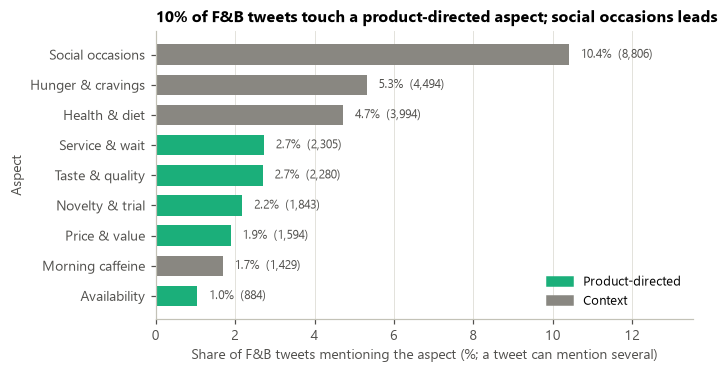

In [21]:
# ------------------------------------------------------------------
# 6.6 What aspects of the experience are discussed? (Figure 3.5, horizontal bar)
# ------------------------------------------------------------------
asp = pd.DataFrame({'tweets': fnb[ASPECT_ORDER].sum()}).assign(share=lambda d: d['tweets'] / len(fnb))
asp['group'] = asp.index.map(ASPECT_GROUP)
asp = asp.sort_values('share')
for a in ASPECT_ORDER:
    keep(f"asp_share_{a.split(' ')[0].lower()}", asp.loc[a, 'share'])
keep('share_any_product_aspect', fnb['any_product_aspect'].mean())
keep('share_no_aspect', (fnb['n_aspects'] == 0).mean())

fig, ax = plt.subplots(figsize=(6.3, 3.4))
ax.barh(asp.index, asp['share'] * 100, color=asp['group'].map(GROUP_COLORS), height=0.68, zorder=2)
for y, (s, n) in enumerate(zip(asp['share'], asp['tweets'])):
    ax.text(s * 100 + 0.3, y, f'{s:.1%}  ({n:,})', va='center', fontsize=8, color=INK)
ax.set_xlabel('Share of F&B tweets mentioning the aspect (%; a tweet can mention several)')
ax.set_ylabel('Aspect')
ax.set_xlim(0, asp['share'].max() * 100 * 1.3)
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=AQUA, label='Product-directed'), Patch(color=GRAY, label='Context')],
          loc='lower right')
top_a = asp.index[-1]
ax.set_title(f'{fnb["any_product_aspect"].mean():.0%} of F&B tweets touch a product-directed aspect; '
             f'{top_a.lower()} leads')
save_fig(fig, 'fig3_5_aspect_volume')

**Reading Figure 3.5.** Only 10.0% of F&B tweets touch a product-directed aspect (taste, price, service, availability or novelty). Context aspects are more common, led by social occasions (10.4%), and 70.5% of the tweets match no aspect at all, which is normal for 140-character messages.

## 7. Main discussion topics (data-driven check)

**Goal:** the aspect dictionary in Section 5 reflects what *we* expected people to talk about. Here we let the data speak and check whether other themes appear.
**Method:** Non-negative Matrix Factorisation (NMF; Lee & Seung, 1999) on TF-IDF weights of the F&B tweets. NMF splits the tweet-term matrix into a small number of topics, each described by its highest-weighted words. We remove English stop words and the dictionary keywords themselves (otherwise the topics would just return our own word list), try 6, 8 and 10 topics, and keep the number whose topics are easiest to name.
**What to look for:** topics that match our aspects (confirmation) and topics that do not (new themes), plus the negative lift of each topic.

In [22]:
# ------------------------------------------------------------------
# 7.1 TF-IDF on the F&B tweets, without stop words and dictionary keywords
# ------------------------------------------------------------------
extra_stop = {'just', 'im', 'got', 'get', 'getting', 'going', 'gonna', 'go', 'day', 'today', 'know', 'really',
              'like', 'want', 'think', 'lol', 'haha', 'oh', 'don', 'dont', 'didn', 'can', 'won', 'quot', 'amp',
              'll', 've', 're', 'thanks', 'thank', 'time', 'good', 'love', 'make', 'need', 'u', 'ur', 'feel',
              'come', 'right', 'way', 'great', 'nice', 'better', 'cream', 'ice', 'iced', 'cup', 'chip', 'chips',
              'mm', 'mmm', 'yum', 'yummy', 'url', 'user', 'wanna', 'did', 'does', 'say', 'said', 'yes', 'yeah'}
pre = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | extra_stop), token_pattern=r'(?u)\b[a-z][a-z]+\b',
                      ngram_range=(1, 2), min_df=15, max_df=0.10)
pre.fit(fnb['text_norm'])
# Drop every term that the F&B dictionary itself would match, so topics are not just our keyword list
lexicon_re = re.compile('|'.join(list(CATEGORIES.values()) + list(BRANDS.values())))
topic_vocab = [t for t in pre.get_feature_names_out() if not lexicon_re.search(t)]
tv_topic = TfidfVectorizer(vocabulary=topic_vocab, token_pattern=r'(?u)\b[a-z][a-z]+\b', ngram_range=(1, 2),
                           sublinear_tf=True, dtype=np.float32)
X_topic = tv_topic.fit_transform(fnb['text_norm'])
vocab = np.array(tv_topic.get_feature_names_out())
print('Topic vocabulary:', X_topic.shape, '| terms removed because they are dictionary keywords:',
      len(pre.get_feature_names_out()) - len(topic_vocab))

# Try several numbers of topics and print their top words
nmf_runs = {}
for k in (6, 8, 10):
    m = NMF(n_components=k, init='nndsvda', random_state=SEED, max_iter=400)
    W = m.fit_transform(X_topic)
    nmf_runs[k] = (m, W)
    print(f'\nk = {k}, reconstruction error = {m.reconstruction_err_:.1f}')
    for t, comp in enumerate(m.components_):
        print(f'  T{t}:', ', '.join(vocab[comp.argsort()[::-1][:8]]))

Topic vocabulary: (84632, 4329) | terms removed because they are dictionary keywords: 1015



k = 6, reconstruction error = 280.3
  T0: work, ready, tomorrow, break, hours, gotta, work tomorrow, finished
  T1: having, family, watching, mom, sunday, fun, having fun, lovely
  T2: morning, sunday, early, start, sunday morning, beautiful, ready, hope
  T3: home, waiting, miss, mom, finally, went, left, came
  T4: making, mom, watching, stop, start, mac, tomorrow, happy
  T5: night, tonight, fun, tomorrow, friends, house, sleep, watching



k = 8, reconstruction error = 279.3
  T0: work, break, tomorrow, ready, hours, work tomorrow, gotta, hour
  T1: having, family, having fun, sunday, late, mom, lovely, break
  T2: morning, sunday, early, start, sunday morning, beautiful, enjoying, enjoy
  T3: home, waiting, finally, came home, mom, came, left, went
  T4: making, mom, stop, watching, mac, start, mommy, blueberry
  T5: night, late, late night, sleep, friday, friday night, fun, movie
  T6: tonight, looking, forward, looking forward, party, movie, wait, family
  T7: watching, house, fun, ready, tomorrow, happy, miss, hot



k = 10, reconstruction error = 278.6
  T0: work, break, tomorrow, hours, work tomorrow, gotta, hour, busy
  T1: having, family, having fun, sunday, late, lovely, mom, break
  T2: morning, sunday, early, start, sunday morning, beautiful, enjoying, woke
  T3: home, waiting, finally, came home, mom, came, left, went
  T4: making, mom, stop, start, mac, mommy, blueberry, making homemade
  T5: night, late, late night, sleep, friday night, friday, movie, bed
  T6: tonight, looking, forward, looking forward, movie, party, family, wait
  T7: fun, happy, bad, tomorrow, miss, hot, best, hope
  T8: watching, movie, tv, waiting, watching tv, sitting, finished, bed
  T9: ready, house, finished, later, party, start, school, waiting


With the food words removed, the topics are not about products at all: they describe **the moments in which people mention food** (work breaks, mornings, late nights, family weekends, cooking at home). The reconstruction error barely changes between 6, 8 and 10 topics, so we keep **k = 8**, the smallest number in which every topic can be given a clear name. Each tweet is assigned to its strongest topic only when that weight exceeds 0.03 (roughly the 75th percentile of the strongest weight); shorter or vaguer tweets are labelled "No clear topic". The eighth topic is built from general mood words (fun, happy, miss, hot) rather than a situation, and we name it honestly as such.

In [23]:
# ------------------------------------------------------------------
# 7.2 Final topic model (k = 8): names, sizes and negative lift
# ------------------------------------------------------------------
K = 8
nmf, W = nmf_runs[K]
TOPIC_NAMES = ['Work and breaks', 'Family and weekend fun', 'Morning start', 'Coming home and waiting',
               'Cooking at home', 'Late nights', 'Plans and anticipation', 'Everyday mood (generic words)']
top_terms = [', '.join(vocab[c.argsort()[::-1][:8]]) for c in nmf.components_]
strength = W.max(axis=1)
fnb['topic'] = np.where(strength > 0.03, np.array(TOPIC_NAMES)[W.argmax(axis=1)], 'No clear topic')

base_neg = fnb['neg'].mean()
rows = []
for name, terms in zip(TOPIC_NAMES + ['No clear topic'], top_terms + ['']):
    inside = fnb['topic'] == name
    r = two_prop(fnb.loc[inside, 'neg'].sum(), inside.sum(), fnb.loc[~inside, 'neg'].sum(), (~inside).sum())
    rows.append({'Topic': name, 'Top terms': terms, 'Tweets': int(inside.sum()), 'Share': inside.mean(),
                 'Negative share': r['p1'], 'Lift vs rest (pp)': 100 * r['diff'],
                 '95% CI (pp)': f"{100 * r['lo']:+.1f} to {100 * r['hi']:+.1f}"})
topic_tbl = pd.DataFrame(rows)
keep('topic_no_clear_share', (fnb['topic'] == 'No clear topic').mean())
for r in rows:
    keep(f"topic_lift_{r['Topic'].split(' ')[0].lower()}", r['Lift vs rest (pp)'], 2)
topic_tbl.style.format({'Share': '{:.1%}', 'Negative share': '{:.1%}', 'Lift vs rest (pp)': '{:+.1f}'}).hide(axis='index')

Topic,Top terms,Tweets,Share,Negative share,Lift vs rest (pp),95% CI (pp)
Work and breaks,"work, break, tomorrow, ready, hours, work tomorrow, gotta, hour",1950,2.3%,48.2%,+13.7,+11.5 to +16.0
Family and weekend fun,"having, family, having fun, sunday, late, mom, lovely, break",1972,2.3%,27.6%,-7.3,-9.3 to -5.3
Morning start,"morning, sunday, early, start, sunday morning, beautiful, enjoying, enjoy",2185,2.6%,28.1%,-6.9,-8.8 to -5.0
Coming home and waiting,"home, waiting, finally, came home, mom, came, left, went",2471,2.9%,38.3%,+3.6,+1.7 to +5.6
Cooking at home,"making, mom, stop, watching, mac, start, mommy, blueberry",1396,1.6%,26.4%,-8.6,-10.9 to -6.2
Late nights,"night, late, late night, sleep, friday, friday night, fun, movie",2587,3.1%,34.0%,-0.8,-2.6 to +1.1
Plans and anticipation,"tonight, looking, forward, looking forward, party, movie, wait, family",2007,2.4%,29.2%,-5.7,-7.7 to -3.6
Everyday mood (generic words),"watching, house, fun, ready, tomorrow, happy, miss, hot",6700,7.9%,33.3%,-1.6,-2.7 to -0.4
No clear topic,,63364,74.9%,35.2%,+1.8,+1.0 to +2.5


**Reading the topic table.** Three quarters of the tweets (74.9%) are too short or vague to load clearly on a topic. Among the rest one topic stands out: food mentioned around **work and breaks** is 48.2% negative, 13.7 pp above the rest of the F&B conversation (95% CI +11.5 to +16.0). Food at home, with family or in the morning is clearly more positive (-6.9 to -8.6 pp). Sentiment depends as much on the *moment* of consumption as on the product itself.

## 8. Diagnostic analysis: why is part of the conversation negative?

**Goal:** find which aspects, moments and words go together with negative tweets (Chapter 1: diagnostic analytics uses hypothesis testing and regression analysis to answer "Why did it happen?").
**Method:**
1. For each aspect, compare its negative share with the rest of the F&B stream: 95% confidence interval for the difference of two proportions (Chapter 4) and a two-proportion z-test (Chapter 5), plus Cohen's *h* as an effect size.
2. Test the four hypotheses fixed in Section 1, with a Holm correction because we run four tests.
3. Fit a logistic regression so that each factor is judged *holding the others constant*.
4. Find the words that separate negative from positive F&B tweets, and check when (time of day) each aspect turns negative.

**What to look for:** differences that are both statistically significant **and** larger than our practical threshold (5 pp, or odds ratio outside 0.8–1.25). This is observational data, so these are associations, not causes (Chapter 1, slide 41).

In [24]:
# ------------------------------------------------------------------
# 8.1 Each aspect vs the rest of the F&B stream
# ------------------------------------------------------------------
PRACTICAL_PP = 5.0
rows = []
for a in ASPECT_ORDER:
    m = fnb[a]
    r = two_prop(fnb.loc[m, 'neg'].sum(), m.sum(), fnb.loc[~m, 'neg'].sum(), (~m).sum())
    p_in, lo_in, hi_in = prop_ci(fnb.loc[m, 'neg'].sum(), m.sum())
    rows.append({'Aspect': a, 'Group': ASPECT_GROUP[a], 'Tweets': int(m.sum()),
                 'Negative share': p_in, 'CI low': lo_in, 'CI high': hi_in,
                 'Rest of F&B': r['p2'], 'Lift (pp)': 100 * r['diff'],
                 'Lift CI low': 100 * r['lo'], 'Lift CI high': 100 * r['hi'],
                 'z': r['z'], 'p-value': r['p_value'], "Cohen's h": cohens_h(r['p1'], r['p2'])})
aspect_tbl = pd.DataFrame(rows).set_index('Aspect')
aspect_tbl['Practically important'] = aspect_tbl['Lift (pp)'].abs() >= PRACTICAL_PP
for a in ASPECT_ORDER:
    tag = a.split(' ')[0].lower()
    keep(f'asp_neg_{tag}', aspect_tbl.loc[a, 'Negative share'])
    keep(f'asp_lift_{tag}', aspect_tbl.loc[a, 'Lift (pp)'], 2)
    keep(f'asp_lift_lo_{tag}', aspect_tbl.loc[a, 'Lift CI low'], 2)
    keep(f'asp_lift_hi_{tag}', aspect_tbl.loc[a, 'Lift CI high'], 2)
    keep(f'asp_n_{tag}', aspect_tbl.loc[a, 'Tweets'])
keep('fnb_neg_overall', fnb['neg'].mean())
aspect_tbl.drop(columns=['CI low', 'CI high']).style.format(
    {'Tweets': '{:,}', 'Negative share': '{:.1%}', 'Rest of F&B': '{:.1%}', 'Lift (pp)': '{:+.1f}',
     'Lift CI low': '{:+.1f}', 'Lift CI high': '{:+.1f}', 'z': '{:.1f}', 'p-value': '{:.1e}', "Cohen's h": '{:+.2f}'})

,Group,Tweets,Negative share,Rest of F&B,Lift (pp),Lift CI low,Lift CI high,z,p-value,Cohen's h,Practically important
Aspect,,,,,,,,,,,
Taste & quality,Product-directed,"2,280",35.7%,34.7%,+1.0,-1.0,+3.0,1.0,3.2e-01,+0.02,False
Price & value,Product-directed,"1,594",40.3%,34.7%,+5.6,+3.2,+8.0,4.7,3.2e-06,+0.12,True
Service & wait,Product-directed,"2,305",40.0%,34.6%,+5.4,+3.3,+7.4,5.3,9.2e-08,+0.11,True
Availability,Product-directed,884,79.6%,34.3%,+45.3,+42.7,+48.0,28.2,2.0e-174,+0.95,True
Novelty & trial,Product-directed,"1,843",27.7%,34.9%,-7.2,-9.3,-5.1,-6.4,1.3e-10,-0.16,True
Hunger & cravings,Context,"4,494",64.6%,33.1%,+31.5,+30.0,+32.9,43.1,0.0e+00,+0.64,True
Health & diet,Context,"3,994",57.2%,33.7%,+23.5,+22.0,+25.1,30.5,7.0e-204,+0.48,True
Morning caffeine,Context,"1,429",28.3%,34.9%,-6.6,-9.0,-4.3,-5.2,1.9e-07,-0.14,True
Social occasions,Context,"8,806",27.0%,35.7%,-8.6,-9.6,-7.6,-16.1,3.6e-58,-0.19,True


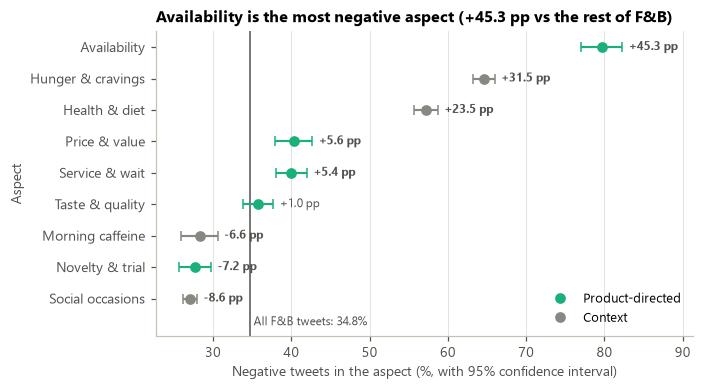

In [25]:
# Figure 4.1: negative share per aspect with 95% CI (dot plot with error bars)
plot_tbl = aspect_tbl.sort_values('Negative share')
fig, ax = plt.subplots(figsize=(6.3, 3.6))
ys = np.arange(len(plot_tbl))
base = fnb['neg'].mean() * 100
ax.axvline(base, color=INK, lw=1, zorder=1)
ax.text(base + 0.4, -0.85, f'All F&B tweets: {base:.1f}%', fontsize=8, color=INK)
for y, (a, r) in zip(ys, plot_tbl.iterrows()):
    c = GROUP_COLORS[r['Group']]
    ax.errorbar(r['Negative share'] * 100, y, xerr=[[100 * (r['Negative share'] - r['CI low'])],
                [100 * (r['CI high'] - r['Negative share'])]], fmt='o', color=c, ms=6, capsize=3, lw=1.4, zorder=3)
    ax.text(r['CI high'] * 100 + 0.8, y, f"{r['Lift (pp)']:+.1f} pp", va='center', fontsize=8,
            color=INK, fontweight='bold' if r['Practically important'] else 'normal')
ax.set_yticks(ys, plot_tbl.index)
ax.set_ylim(-1.2, len(plot_tbl) - 0.5)
ax.set_xlabel('Negative tweets in the aspect (%, with 95% confidence interval)')
ax.set_ylabel('Aspect')
ax.set_xlim(plot_tbl['CI low'].min() * 100 - 3, plot_tbl['CI high'].max() * 100 + 9)
ax.grid(axis='y', visible=False)
ax.legend(handles=[mpl.lines.Line2D([], [], marker='o', ls='', color=AQUA, label='Product-directed'),
                   mpl.lines.Line2D([], [], marker='o', ls='', color=GRAY, label='Context')],
          loc='lower right')
worst = plot_tbl.index[-1]
ax.set_title(f'{worst} is the most negative aspect ({plot_tbl.loc[worst, "Lift (pp)"]:+.1f} pp vs the rest of F&B)')
save_fig(fig, 'fig4_1_aspect_negative_share_ci')

**Reading Figure 4.1.** Availability problems are by far the most negative aspect: 79.6% of tweets about something being sold out, closed or unavailable are negative (+45.3 pp). Price and value (+5.6 pp, CI +3.2 to +8.0) and service and waiting (+5.4 pp, CI +3.3 to +7.4) also pass the 5 pp threshold, while taste and quality is not different from the rest (+1.0 pp, the CI crosses zero). Talk about trying something new is *less* negative than average (-7.2 pp), which is good news for a launch.

In [26]:
# ------------------------------------------------------------------
# 8.2 Hypotheses H1-H4 with Holm correction
# ------------------------------------------------------------------
hyp = []
for h, a in [('H1', 'Service & wait'), ('H2', 'Price & value'), ('H3', 'Morning caffeine')]:
    r = aspect_tbl.loc[a]
    hyp.append({'Hypothesis': h, 'Comparison': f'{a} vs rest of F&B', 'Difference (pp)': r['Lift (pp)'],
                '95% CI (pp)': f"{r['Lift CI low']:+.1f} to {r['Lift CI high']:+.1f}", 'z': r['z'],
                'p-value': r['p-value'], "Cohen's h": r["Cohen's h"]})

# H4: difference-in-differences of the lift between launch week and baseline
def lift_parts(per):
    f, a = fnb[fnb['period'] == per], df[df['period'] == per]
    return f['neg'].mean(), len(f), a['neg'].mean(), len(a)
pf_l, nf_l, pa_l, na_l = lift_parts('Launch week')
pf_b, nf_b, pa_b, na_b = lift_parts('Baseline')
did = (pf_l - pa_l) - (pf_b - pa_b)
se_did = np.sqrt(sum(p * (1 - p) / n for p, n in [(pf_l, nf_l), (pa_l, na_l), (pf_b, nf_b), (pa_b, na_b)]))
z_did = did / se_did
hyp.append({'Hypothesis': 'H4', 'Comparison': 'F&B lift, launch week vs baseline (diff-in-diff)',
            'Difference (pp)': 100 * did, '95% CI (pp)': f'{100 * (did - 1.96 * se_did):+.1f} to {100 * (did + 1.96 * se_did):+.1f}',
            'z': z_did, 'p-value': 2 * stats.norm.sf(abs(z_did)), "Cohen's h": np.nan})
hyp_tbl = pd.DataFrame(hyp).set_index('Hypothesis')
hyp_tbl['Holm-adjusted p'] = multipletests(hyp_tbl['p-value'], method='holm')[1]
hyp_tbl['Statistically significant'] = hyp_tbl['Holm-adjusted p'] < 0.05
hyp_tbl['Practically important (|diff| >= 5 pp)'] = hyp_tbl['Difference (pp)'].abs() >= PRACTICAL_PP
for h in hyp_tbl.index:
    keep(f'{h}_diff_pp', hyp_tbl.loc[h, 'Difference (pp)'], 2)
    keep(f'{h}_p_holm', hyp_tbl.loc[h, 'Holm-adjusted p'], 6)
    keep(f'{h}_ci', hyp_tbl.loc[h, '95% CI (pp)'])
hyp_tbl.style.format({'Difference (pp)': '{:+.2f}', 'z': '{:.2f}', 'p-value': '{:.2e}', "Cohen's h": '{:+.2f}',
                      'Holm-adjusted p': '{:.2e}'})

,Comparison,Difference (pp),95% CI (pp),z,p-value,Cohen's h,Holm-adjusted p,Statistically significant,Practically important (|diff| >= 5 pp)
Hypothesis,,,,,,,,,
H1,Service & wait vs rest of F&B,+5.37,+3.3 to +7.4,5.34,9.22e-08,+0.11,3.69e-07,True,True
H2,Price & value vs rest of F&B,+5.61,+3.2 to +8.0,4.66,3.22e-06,+0.12,6.44e-06,True,True
H3,Morning caffeine vs rest of F&B,-6.61,-9.0 to -4.3,-5.21,1.93e-07,-0.14,5.80e-07,True,True
H4,"F&B lift, launch week vs baseline (diff-in-diff)",-0.33,-1.0 to +0.4,-0.89,3.72e-01,+nan,3.72e-01,False,False


**Reading the hypothesis tests.** H1, H2 and H3 stay significant after the Holm correction and each difference is larger than 5 pp, so they are significant both statistically and practically. H4 is not: the F&B lift in launch week differs from the baseline by only -0.3 pp (95% CI -1.0 to +0.4, p = 0.37). The launch week did not make the category conversation more negative than usual.

In [27]:
# ------------------------------------------------------------------
# 8.3 Logistic regression: each factor holding the others constant
# ------------------------------------------------------------------
SAFE = {'Taste & quality': 'a_taste', 'Price & value': 'a_price', 'Service & wait': 'a_service',
        'Availability': 'a_avail', 'Novelty & trial': 'a_novelty', 'Hunger & cravings': 'a_hunger',
        'Health & diet': 'a_health', 'Morning caffeine': 'a_morning', 'Social occasions': 'a_social'}
reg = fnb[['neg', 'n_words', 'has_url', 'has_mention', 'weekend', 'daypart', 'date'] + ASPECT_ORDER].rename(columns=SAFE)
reg['topic_work'] = (fnb['topic'] == 'Work and breaks').astype(int)
reg['log_words'] = np.log(reg['n_words'])
reg['daypart'] = reg['daypart'].astype(str)
reg['day'] = reg['date'].dt.strftime('%m%d')
for c in list(SAFE.values()) + ['has_url', 'has_mention', 'weekend']:
    reg[c] = reg[c].astype(int)
# Day fixed effects C(day) absorb collection differences between days (and therefore also weekday/weekend)
formula = ('neg ~ ' + ' + '.join(SAFE.values()) + " + topic_work + C(daypart, Treatment('Afternoon (12-17h)'))"
           ' + log_words + has_url + has_mention + C(day)')
logit = smf.logit(formula, data=reg).fit(disp=False, maxiter=200)

LABELS = {v: k for k, v in SAFE.items()}
LABELS.update({'topic_work': 'Topic: work and breaks', 'weekend': 'Weekend', 'log_words': 'log(words)',
               'has_url': 'Contains a link', 'has_mention': 'Mentions a user'})
ci = logit.conf_int()
or_tbl = pd.DataFrame({'Odds ratio': np.exp(logit.params), 'CI low': np.exp(ci[0]), 'CI high': np.exp(ci[1]),
                       'p-value': logit.pvalues})
or_tbl = or_tbl[~or_tbl.index.str.startswith(('C(day)', 'Intercept'))]
or_tbl.index = [LABELS.get(i, i.replace("C(daypart, Treatment('Afternoon (12-17h)'))[T.", 'Daypart: ').rstrip(']'))
                for i in or_tbl.index]
or_tbl['Practically important'] = (or_tbl['Odds ratio'] < 0.8) | (or_tbl['Odds ratio'] > 1.25)
for i in or_tbl.index:
    keep('OR_' + re.sub(r'[^a-z0-9]+', '_', i.lower()).strip('_'), or_tbl.loc[i, 'Odds ratio'], 3)
keep('logit_pseudo_r2', logit.prsquared); keep('logit_n', int(logit.nobs))
print(f'n = {int(logit.nobs):,}, McFadden pseudo R2 = {logit.prsquared:.3f}, '
      f'{len(logit.params) - len(or_tbl) - 1} day fixed effects not shown')
or_tbl.sort_values('Odds ratio', ascending=False).style.format(
    {'Odds ratio': '{:.2f}', 'CI low': '{:.2f}', 'CI high': '{:.2f}', 'p-value': '{:.1e}'})

n = 84,632, McFadden pseudo R2 = 0.051, 38 day fixed effects not shown


,Odds ratio,CI low,CI high,p-value,Practically important
Availability,7.18,6.08,8.49,9.5e-119,True
Hunger & cravings,3.72,3.49,3.97,0.0e+00,True
Health & diet,2.36,2.21,2.52,8.8e-143,True
Topic: work and breaks,1.57,1.43,1.72,1.4e-21,True
log(words),1.55,1.51,1.60,2.9e-189,True
Price & value,1.21,1.09,1.34,4.0e-04,False
Service & wait,1.11,1.02,1.21,2.1e-02,False
Taste & quality,1.01,0.93,1.11,7.9e-01,False
Daypart: Morning (6-11h),0.98,0.93,1.02,3.4e-01,False
Daypart: Evening (18-23h),0.95,0.91,1.00,4.6e-02,False


**Reading the odds ratios** (like a regression slope in Chapter 7). Holding the other factors and the day constant, a tweet that mentions availability has 7.2 times the odds of being negative (95% CI 6.1 to 8.5); hunger (3.7) and health (2.4) follow, and the work-and-breaks topic keeps an odds ratio of 1.57. Price (1.21) and service (1.11) remain significant but shrink once the other factors are held constant, so part of their raw gap comes from overlap with hunger and time of day. Novelty (0.66), social occasions (0.64) and morning caffeine (0.71) lower the odds. The McFadden pseudo R-squared is only 0.05: aspects and timing explain a small part of sentiment, and most of it lives in the wording, which is what the classifier in Section 9 uses.

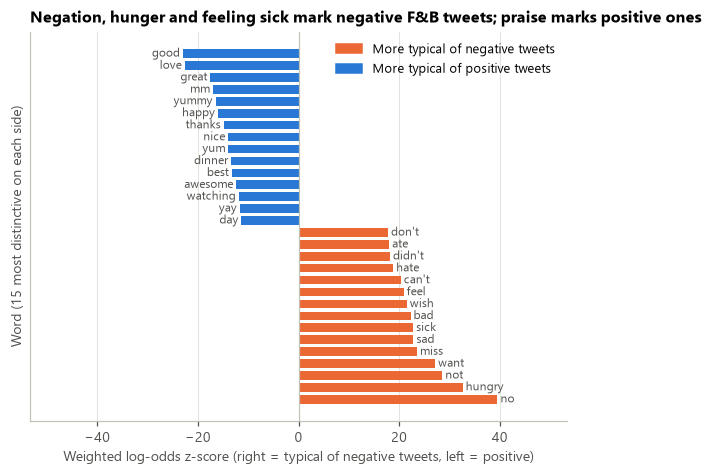

In [28]:
# ------------------------------------------------------------------
# 8.4 Words that separate negative from positive F&B tweets
#     (weighted log-odds with an informative Dirichlet prior, Monroe et al. 2008)
# ------------------------------------------------------------------
KEEP_NEG_WORDS = {'no', 'not', 'nothing', 'never', 'cannot', 'nobody'}
fw_stop = list((ENGLISH_STOP_WORDS - KEEP_NEG_WORDS) | {'_url_', '_user_', 'quot', 'amp', 'im'})
cv_fw = CountVectorizer(token_pattern=r"(?u)\b[a-z][a-z']+\b", stop_words=fw_stop, min_df=20)
C_fnb = cv_fw.fit_transform(fnb['text_norm'])
words = cv_fw.get_feature_names_out()
y_neg = np.asarray(C_fnb[fnb['neg'].to_numpy() == 1].sum(axis=0)).ravel()
y_pos = np.asarray(C_fnb[fnb['neg'].to_numpy() == 0].sum(axis=0)).ravel()
bg = np.asarray(cv_fw.transform(df['text_norm']).sum(axis=0)).ravel()     # background: the whole clean corpus
A0 = 1000.0
alpha = bg / bg.sum() * A0
n_neg, n_pos = y_neg.sum(), y_pos.sum()
delta = (np.log((y_neg + alpha) / (n_neg + A0 - y_neg - alpha))
         - np.log((y_pos + alpha) / (n_pos + A0 - y_pos - alpha)))
zscore = delta / np.sqrt(1 / (y_neg + alpha) + 1 / (y_pos + alpha))
fw = pd.DataFrame({'word': words, 'z': zscore, 'neg_count': y_neg, 'pos_count': y_pos}).set_index('word')
top_neg_words = fw.nlargest(15, 'z'); top_pos_words = fw.nsmallest(15, 'z')
keep('fw_top_neg', ', '.join(top_neg_words.index[:10])); keep('fw_top_pos', ', '.join(top_pos_words.index[:10]))

fw_plot = pd.concat([top_pos_words, top_neg_words.iloc[::-1]]).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.3, 4.6))
colors = [NEG if z > 0 else POS for z in fw_plot['z']]
ax.barh(np.arange(len(fw_plot)), fw_plot['z'], color=colors, height=0.72, zorder=2)
for y, (w, z) in enumerate(zip(fw_plot.index, fw_plot['z'])):
    ax.text(z + (0.6 if z > 0 else -0.6), y, w, va='center', ha='left' if z > 0 else 'right', fontsize=8, color=INK)
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_yticks([])
ax.set_xlabel('Weighted log-odds z-score (right = typical of negative tweets, left = positive)')
ax.set_ylabel('Word (15 most distinctive on each side)')
lim = np.abs(fw_plot['z']).max() * 1.35
ax.set_xlim(-lim, lim)
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=NEG, label='More typical of negative tweets'),
                   Patch(color=POS, label='More typical of positive tweets')], loc='upper right')
ax.set_title('Negation, hunger and feeling sick mark negative F&B tweets; praise marks positive ones')
save_fig(fig, 'fig4_3_distinctive_words')

**Reading Figure 4.3.** The words most typical of negative F&B tweets are negations (*no*, *not*, *can't*, *don't*), wanting and missing (*hungry*, *want*, *miss*, *wish*) and feeling unwell (*sick*, *sad*, *feel*). Positive tweets are dominated by praise (*good*, *love*, *great*, *yummy*) and thanks. Negative F&B talk is mostly about unmet wants (no food, no time, nothing open) rather than about a bad product.

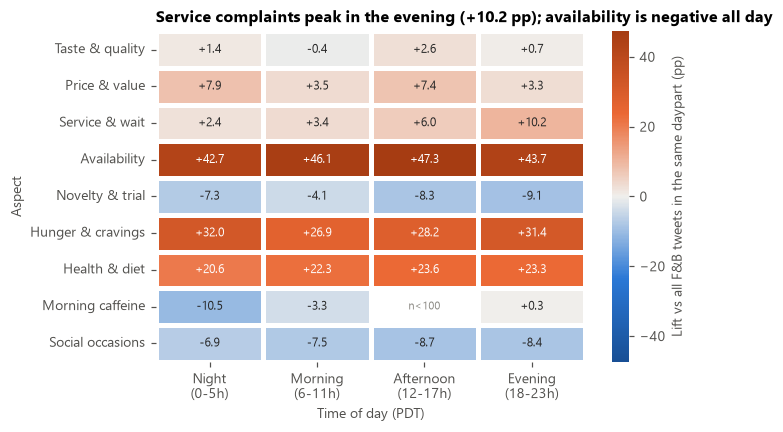

In [29]:
# ------------------------------------------------------------------
# 8.5 When does each aspect turn negative? (Figure 4.2, heatmap of lift by time of day)
# ------------------------------------------------------------------
MIN_N = 100
dp_base = fnb.groupby('daypart', observed=True)['neg'].mean()
heat, counts = pd.DataFrame(index=ASPECT_ORDER, columns=DAYPARTS, dtype=float), pd.DataFrame(index=ASPECT_ORDER, columns=DAYPARTS, dtype=float)
for a in ASPECT_ORDER:
    g = fnb[fnb[a]].groupby('daypart', observed=True)['neg'].agg(['mean', 'size'])
    for dp in DAYPARTS:
        if dp in g.index:
            heat.loc[a, dp] = 100 * (g.loc[dp, 'mean'] - dp_base[dp])
            counts.loc[a, dp] = g.loc[dp, 'size']
heat_masked = heat.where(counts >= MIN_N)
keep('heat_max_cell', f"{heat_masked.stack().idxmax()[0]} / {heat_masked.stack().idxmax()[1]}")
keep('heat_max_value', heat_masked.stack().max(), 2)

div_cmap = mpl.colors.LinearSegmentedColormap.from_list('pos_neg', ['#184f95', POS, '#f0efec', NEG, '#a63c12'])
vmax = np.nanmax(np.abs(heat_masked.to_numpy()))
fig, ax = plt.subplots(figsize=(6.3, 3.9))
sns.heatmap(heat_masked, cmap=div_cmap, center=0, vmin=-vmax, vmax=vmax, annot=True, fmt='+.1f',
            annot_kws={'fontsize': 8}, linewidths=2, linecolor='white', ax=ax,
            cbar_kws={'label': 'Lift vs all F&B tweets in the same daypart (pp)'})
for (i, a) in enumerate(ASPECT_ORDER):
    for (j, dp) in enumerate(DAYPARTS):
        if counts.loc[a, dp] < MIN_N:
            ax.text(j + 0.5, i + 0.5, f'n<{MIN_N}', ha='center', va='center', fontsize=7, color=GRAY)
ax.set_xlabel('Time of day (PDT)')
ax.set_ylabel('Aspect')
ax.set_xticklabels([d.replace(' (', '\n(') for d in DAYPARTS], rotation=0)
ax.grid(False)
svc_evening = heat_masked.loc['Service & wait', 'Evening (18-23h)']
keep('heat_service_evening', svc_evening, 2)
keep('heat_price_night', heat_masked.loc['Price & value', 'Night (0-5h)'], 2)
ax.set_title(f'Service complaints peak in the evening ({svc_evening:+.1f} pp); availability is negative all day')
save_fig(fig, 'fig4_2_aspect_daypart_heatmap')

**Reading Figure 4.2.** Service complaints are most negative in the evening (+10.2 pp), when queues and delivery delays are likeliest, and price complaints at night and in the afternoon (+7.9 and +7.4 pp). Availability is strongly negative at every time of day. Morning-caffeine tweets posted at night (PDT) are the most positive (-10.5 pp); timestamps are Pacific time, so many of them are probably morning tweets from Europe, which is why we do not over-read time-of-day effects in this dataset.

## 9. Predictive analysis: can a model label next week's tweets?

**Goal:** the marketing team needs to monitor next week's conversation without reading every tweet. We build a classifier that predicts whether a tweet is negative, trained only on the past (Chapter 1: predictive analytics answers "What is likely to happen?"; Chapter 7: "prediction refers to future values").

**Train/test split: by time, not at random.** The model will be used on tweets that do not exist yet, so the honest test is to train on earlier weeks and evaluate on a later week:

| Set | Dates (2009) | Role |
|---|---|---|
| Train | 6 Apr – 31 May (baseline) | fit the models |
| Validation | 1 – 7 Jun (launch week) | choose hyper-parameters and the decision threshold |
| (gap) | 8 – 13 Jun | no data collected; acts as a buffer between tuning and testing |
| Test | 14 – 16 Jun 08:40 (next week) | used **once**, at the very end |

A random split would mix tweets from the same days (and the same conversations) into train and test, so it would tell us how well the model remembers a period rather than how well it handles a new one. We still run a random 80/20 split in 9.5, only as a comparison. Exact duplicates were already removed in Section 4, so no test tweet has an identical copy in the training set.

**Models.** A *Dummy* classifier that always predicts the majority class gives the floor. The **baseline** is Multinomial Naive Bayes on word counts, the classic baseline for this dataset (Go et al., 2009). The **more advanced model** is Logistic Regression on TF-IDF weights of words *and* word pairs: it is discriminative rather than generative, word pairs capture negation ("not good", "no coffee"), its regularisation strength is tuned on the validation week, and its probabilities let us choose a threshold. We keep stop words such as *not* and *no*, because they carry sentiment.

In [30]:
# ------------------------------------------------------------------
# 9.1 Time-based split
# ------------------------------------------------------------------
train, val, test = (df[df['period'] == p] for p in PERIODS)
y_tr, y_va, y_te = (d['neg'].to_numpy() for d in (train, val, test))
split_tbl = pd.DataFrame({
    'Set': ['Train', 'Validation', 'Test'],
    'Dates': [f"{d['dt'].min():%d %b} - {d['dt'].max():%d %b %H:%M}" for d in (train, val, test)],
    'Tweets': [len(d) for d in (train, val, test)],
    'Share of modelling data': [len(d) / (len(train) + len(val) + len(test)) for d in (train, val, test)],
    'Negative share': [d['neg'].mean() for d in (train, val, test)],
    'F&B tweets': [int(d['is_fnb'].sum()) for d in (train, val, test)]})
for _, r in split_tbl.iterrows():
    keep(f"split_n_{r['Set'].lower()}", r['Tweets']); keep(f"split_neg_{r['Set'].lower()}", r['Negative share'])
split_tbl.style.format({'Tweets': '{:,}', 'Share of modelling data': '{:.1%}', 'Negative share': '{:.1%}',
                        'F&B tweets': '{:,}'}).hide(axis='index')

Set,Dates,Tweets,Share of modelling data,Negative share,F&B tweets
Train,06 Apr - 31 May 23:59,"653,345",51.3%,39.6%,"44,184"
Validation,01 Jun - 07 Jun 21:12,"469,953",36.9%,39.9%,"30,921"
Test,14 Jun - 16 Jun 08:40,"150,736",11.8%,40.9%,"9,527"


In [31]:
# ------------------------------------------------------------------
# 9.2 Features: fitted on the training weeks only
# ------------------------------------------------------------------
TOKEN = r"(?u)\b\w[\w']*\b|[!?]"        # keeps "don't", "can't" and the marks ! and ?
t0 = time.time()
cv_nb = CountVectorizer(token_pattern=TOKEN, lowercase=False, min_df=3, dtype=np.float32)
Xc_tr = cv_nb.fit_transform(train['text_norm']); Xc_va = cv_nb.transform(val['text_norm']); Xc_te = cv_nb.transform(test['text_norm'])
tv_lr = TfidfVectorizer(token_pattern=TOKEN, lowercase=False, ngram_range=(1, 2), min_df=3, max_df=0.5,
                        max_features=300_000, sublinear_tf=True, dtype=np.float32)
Xt_tr = tv_lr.fit_transform(train['text_norm']); Xt_va = tv_lr.transform(val['text_norm']); Xt_te = tv_lr.transform(test['text_norm'])
print(f'Bag-of-words (NB): {Xc_tr.shape[1]:,} words | TF-IDF (LR): {Xt_tr.shape[1]:,} words and word pairs '
      f'| {time.time() - t0:.0f}s')
_ = keep('n_features_nb', Xc_tr.shape[1]), keep('n_features_lr', Xt_tr.shape[1])

Bag-of-words (NB): 47,118 words | TF-IDF (LR): 300,000 words and word pairs | 47s


In [32]:
# ------------------------------------------------------------------
# 9.3 Tune on the validation week (ranking quality = ROC-AUC)
# ------------------------------------------------------------------
def neg_f1(y, p_neg, thr):
    return f1_score(y, (p_neg >= thr).astype(int), pos_label=1)

tuning = []
nb_models = {}
for a in (0.1, 0.3, 1.0, 3.0, 10.0):
    m = MultinomialNB(alpha=a).fit(Xc_tr, y_tr)
    p = m.predict_proba(Xc_va)[:, 1]
    nb_models[a] = m
    tuning.append({'Model': 'Naive Bayes', 'Setting': f'alpha = {a}', 'Val ROC-AUC': roc_auc_score(y_va, p),
                   'Val negative F1 (0.5)': neg_f1(y_va, p, 0.5)})
lr_models = {}
for C in (0.5, 1.0, 2.0, 4.0):
    t0 = time.time()
    m = LogisticRegression(C=C, solver='liblinear', class_weight='balanced', max_iter=1000).fit(Xt_tr, y_tr)
    p = m.predict_proba(Xt_va)[:, 1]
    lr_models[C] = m
    tuning.append({'Model': 'Logistic Regression', 'Setting': f'C = {C}', 'Val ROC-AUC': roc_auc_score(y_va, p),
                   'Val negative F1 (0.5)': neg_f1(y_va, p, 0.5), 'Fit time (s)': time.time() - t0})
tune_tbl = pd.DataFrame(tuning)
best_alpha = max(nb_models, key=lambda a: roc_auc_score(y_va, nb_models[a].predict_proba(Xc_va)[:, 1]))
best_C = max(lr_models, key=lambda c: roc_auc_score(y_va, lr_models[c].predict_proba(Xt_va)[:, 1]))
nb, lr = nb_models[best_alpha], lr_models[best_C]
keep('best_alpha', best_alpha); keep('best_C', best_C)
print(f'Chosen: Naive Bayes alpha = {best_alpha}, Logistic Regression C = {best_C}')
tune_tbl.round(4)

Chosen: Naive Bayes alpha = 3.0, Logistic Regression C = 2.0


,Model,Setting,Val ROC-AUC,Val negative F1 (0.5),Fit time (s)
0,Naive Bayes,alpha = 0.1,0.8423,0.7216,NaN
1,Naive Bayes,alpha = 0.3,0.8445,0.7227,NaN
2,Naive Bayes,alpha = 1.0,0.8466,0.7242,NaN
3,Naive Bayes,alpha = 3.0,0.8475,0.7235,NaN
4,Naive Bayes,alpha = 10.0,0.8458,0.7132,NaN
5,Logistic Regression,C = 0.5,0.8938,0.7773,8.0149
6,Logistic Regression,C = 1.0,0.8968,0.7806,8.6213
7,Logistic Regression,C = 2.0,0.8973,0.7808,12.9781
8,Logistic Regression,C = 4.0,0.8950,0.7774,15.4682


In [33]:
# ------------------------------------------------------------------
# 9.4 Choose the decision threshold on the validation week, then evaluate ONCE on the test week
# ------------------------------------------------------------------
p_va = {'Naive Bayes (baseline)': nb.predict_proba(Xc_va)[:, 1],
        'Logistic Regression (advanced)': lr.predict_proba(Xt_va)[:, 1]}
grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
THR = {name: float(grid[np.argmax([neg_f1(y_va, p, t) for t in grid])]) for name, p in p_va.items()}
THR['Dummy (majority)'] = 0.5
print('Thresholds chosen on validation (max negative-class F1):', THR)

dummy = DummyClassifier(strategy='most_frequent').fit(Xc_tr, y_tr)
p_te = {'Dummy (majority)': dummy.predict_proba(Xc_te)[:, 1],
        'Naive Bayes (baseline)': nb.predict_proba(Xc_te)[:, 1],
        'Logistic Regression (advanced)': lr.predict_proba(Xt_te)[:, 1]}
MODELS = list(p_te)

def scores(y, p, thr):
    pred = (p >= thr).astype(int)
    prec, rec, f1n, _ = precision_recall_fscore_support(y, pred, pos_label=1, average='binary', zero_division=0)
    return {'Accuracy': accuracy_score(y, pred), 'Negative precision': prec, 'Negative recall': rec,
            'Negative F1': f1n, 'Macro F1': f1_score(y, pred, average='macro'),
            'ROC-AUC': roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5}

# Bootstrap the test set (200 resamples) for 95% CIs of every metric
B = 200
boot_idx = [rng.integers(0, len(y_te), len(y_te)) for _ in range(B)]
rows = []
for name in MODELS:
    base = scores(y_te, p_te[name], THR[name])
    boots = pd.DataFrame([scores(y_te[i], p_te[name][i], THR[name]) for i in boot_idx])
    for metric, v in base.items():
        rows.append({'Model': name, 'Metric': metric, 'Value': v,
                     'CI low': boots[metric].quantile(0.025), 'CI high': boots[metric].quantile(0.975)})
metrics_long = pd.DataFrame(rows)
metrics_tbl = metrics_long.pivot(index='Model', columns='Metric', values='Value').loc[MODELS]
metrics_05 = pd.DataFrame({n: scores(y_te, p_te[n], 0.5) for n in MODELS}).T      # same metrics at threshold 0.5
for name, tag in zip(MODELS, ['dummy', 'nb', 'lr']):
    for metric in metrics_tbl.columns:
        r = metrics_long[(metrics_long['Model'] == name) & (metrics_long['Metric'] == metric)].iloc[0]
        mt = metric.lower().replace(' ', '_').replace('-', '_')
        keep(f'test_{tag}_{mt}', r['Value']); keep(f'test_{tag}_{mt}_lo', r['CI low']); keep(f'test_{tag}_{mt}_hi', r['CI high'])
    keep(f'thr_{tag}', THR[name])
print('Test week, at the thresholds chosen on validation:')
display(metrics_tbl.style.format('{:.3f}'))
print('Same models at the default threshold 0.5:')
metrics_05.style.format('{:.3f}')

Thresholds chosen on validation (max negative-class F1): {'Naive Bayes (baseline)': 0.37, 'Logistic Regression (advanced)': 0.44, 'Dummy (majority)': 0.5}


Test week, at the thresholds chosen on validation:


Metric,Accuracy,Macro F1,Negative F1,Negative precision,Negative recall,ROC-AUC
Model,,,,,,
Dummy (majority),0.591,0.371,0.000,0.000,0.000,0.500
Naive Bayes (baseline),0.766,0.763,0.737,0.683,0.800,0.846
Logistic Regression (advanced),0.810,0.808,0.785,0.733,0.843,0.896


Same models at the default threshold 0.5:


,Accuracy,Negative precision,Negative recall,Negative F1,Macro F1,ROC-AUC
Dummy (majority),0.591,0.000,0.000,0.000,0.371,0.500
Naive Bayes (baseline),0.779,0.733,0.721,0.727,0.770,0.846
Logistic Regression (advanced),0.817,0.760,0.807,0.783,0.812,0.896


**Reading the test results.** On the held-out week, Logistic Regression reaches 81.0% accuracy (95% CI 80.8% to 81.3%), a negative-class F1 of 0.785 and a ROC-AUC of 0.896, against 76.6%, 0.737 and 0.846 for Naive Bayes and 59.1% accuracy for the dummy. At the threshold chosen on validation it catches 84.3% of negative tweets. Validation and test AUC are almost identical (0.897 vs 0.896), so the model did not degrade from one week to the next.

In [34]:
# McNemar test: the two models are scored on the SAME test tweets, so the comparison is paired
pred_nb = (p_te['Naive Bayes (baseline)'] >= THR['Naive Bayes (baseline)']).astype(int)
pred_lr = (p_te['Logistic Regression (advanced)'] >= THR['Logistic Regression (advanced)']).astype(int)
nb_ok, lr_ok = pred_nb == y_te, pred_lr == y_te
b = int((nb_ok & ~lr_ok).sum())        # NB right, LR wrong
c = int((~nb_ok & lr_ok).sum())        # LR right, NB wrong
mc = mcnemar([[int((nb_ok & lr_ok).sum()), b], [c, int((~nb_ok & ~lr_ok).sum())]], exact=False, correction=True)
n_te = len(y_te)
diff = (c - b) / n_te
se_diff = np.sqrt(b + c - (c - b) ** 2 / n_te) / n_te
keep('mcnemar_b', b); keep('mcnemar_c', c); keep('mcnemar_chi2', mc.statistic, 1); keep('mcnemar_p', mc.pvalue, 8)
keep('acc_gain_lr_vs_nb', diff); keep('acc_gain_lo', diff - 1.96 * se_diff); keep('acc_gain_hi', diff + 1.96 * se_diff)
print(f'Tweets only NB gets right: {b:,} | only LR gets right: {c:,}')
print(f'McNemar chi2 = {mc.statistic:.1f}, p = {mc.pvalue:.2g}; accuracy gain of LR = {diff:+.2%} '
      f'(95% CI {diff - 1.96 * se_diff:+.2%} to {diff + 1.96 * se_diff:+.2%}), '
      f'i.e. about {round(diff * 10000):,} fewer mislabelled tweets per 10,000')

Tweets only NB gets right: 7,241 | only LR gets right: 13,871
McNemar chi2 = 2081.5, p = 0; accuracy gain of LR = +4.40% (95% CI +4.21% to +4.59%), i.e. about 440 fewer mislabelled tweets per 10,000


**Reading the McNemar test.** On the same 150,736 test tweets, 13,871 are labelled correctly only by LR and 7,241 only by NB. The paired accuracy gain is +4.4 pp (95% CI +4.2 to +4.6), about 440 fewer mislabelled tweets per 10,000, which justifies the slightly more complex model.

In [35]:
# ------------------------------------------------------------------
# 9.5 Robustness: random split, F&B vs other tweets, seen vs new users, an F&B-only model
# ------------------------------------------------------------------
t0 = time.time()
model_df = pd.concat([train, val, test])
r_tr, r_te = train_test_split(model_df, test_size=0.2, stratify=model_df['neg'], random_state=SEED)
tv_rand = TfidfVectorizer(**tv_lr.get_params())
lr_rand = LogisticRegression(C=best_C, solver='liblinear', class_weight='balanced', max_iter=1000)
lr_rand.fit(tv_rand.fit_transform(r_tr['text_norm']), r_tr['neg'])
p_rand = lr_rand.predict_proba(tv_rand.transform(r_te['text_norm']))[:, 1]
rand_scores = scores(r_te['neg'].to_numpy(), p_rand, THR['Logistic Regression (advanced)'])
for k_, v in rand_scores.items():
    keep(f"random_lr_{k_.lower().replace(' ', '_').replace('-', '_')}", v)
print(f'Random 80/20 split refit: {time.time() - t0:.0f}s')

p_lr = p_te['Logistic Regression (advanced)']
thr_lr = THR['Logistic Regression (advanced)']
fnb_mask = test['is_fnb'].to_numpy()
seen_users = set(train['user']) | set(val['user'])
seen_mask = test['user'].isin(seen_users).to_numpy()
keep('test_share_seen_users', seen_mask.mean())

# F&B-only model: same recipe, trained on the F&B tweets of the training weeks
f_tr, f_te = train[train['is_fnb']], test[test['is_fnb']]
tv_f = TfidfVectorizer(**tv_lr.get_params())
lr_f = LogisticRegression(C=best_C, solver='liblinear', class_weight='balanced', max_iter=1000)
lr_f.fit(tv_f.fit_transform(f_tr['text_norm']), f_tr['neg'])
p_f = lr_f.predict_proba(tv_f.transform(f_te['text_norm']))[:, 1]
thr_f = THR['Logistic Regression (advanced)']

robust = pd.DataFrame({
    'Time split, all test tweets (main result)': scores(y_te, p_lr, thr_lr),
    'Random 80/20 split': rand_scores,
    'Time split, F&B test tweets': scores(y_te[fnb_mask], p_lr[fnb_mask], thr_lr),
    'Time split, non-F&B test tweets': scores(y_te[~fnb_mask], p_lr[~fnb_mask], thr_lr),
    'Time split, users seen in training': scores(y_te[seen_mask], p_lr[seen_mask], thr_lr),
    'Time split, new users': scores(y_te[~seen_mask], p_lr[~seen_mask], thr_lr),
    'F&B-only model on F&B test tweets': scores(f_te['neg'].to_numpy(), p_f, thr_f)}).T
robust.insert(0, 'Tweets', [len(y_te), len(r_te), fnb_mask.sum(), (~fnb_mask).sum(), seen_mask.sum(),
                            (~seen_mask).sum(), len(f_te)])
for idx, tag in zip(robust.index, ['main', 'random', 'fnb', 'nonfnb', 'seen', 'new', 'fnbonly']):
    keep(f'robust_{tag}_auc', robust.loc[idx, 'ROC-AUC']); keep(f'robust_{tag}_negf1', robust.loc[idx, 'Negative F1'])
    keep(f'robust_{tag}_acc', robust.loc[idx, 'Accuracy'])
robust.style.format({'Tweets': '{:,}', **{c: '{:.3f}' for c in robust.columns[1:]}})

Random 80/20 split refit: 68s


,Tweets,Accuracy,Negative precision,Negative recall,Negative F1,Macro F1,ROC-AUC
"Time split, all test tweets (main result)","150,736",0.810,0.733,0.843,0.785,0.808,0.896
Random 80/20 split,"254,807",0.820,0.742,0.843,0.789,0.816,0.903
"Time split, F&B test tweets","9,527",0.811,0.716,0.806,0.758,0.802,0.886
"Time split, non-F&B test tweets","141,209",0.810,0.734,0.846,0.786,0.808,0.896
"Time split, users seen in training","88,298",0.811,0.726,0.838,0.778,0.807,0.896
"Time split, new users","62,438",0.809,0.743,0.851,0.793,0.808,0.895
F&B-only model on F&B test tweets,"9,527",0.774,0.656,0.813,0.726,0.767,0.862


**Reading the robustness table.** The random 80/20 split gives a slightly higher AUC (0.903 vs 0.896): mixing days lets the model see the same week's topics, so a random split would have overstated performance. On F&B tweets the general model keeps an AUC of 0.886 and beats a model trained only on F&B tweets (0.862), because 653k general tweets teach it more language than 44k F&B ones. Users already seen in training (58.6% of test tweets) and new users get the same scores, so the model is not memorising people.

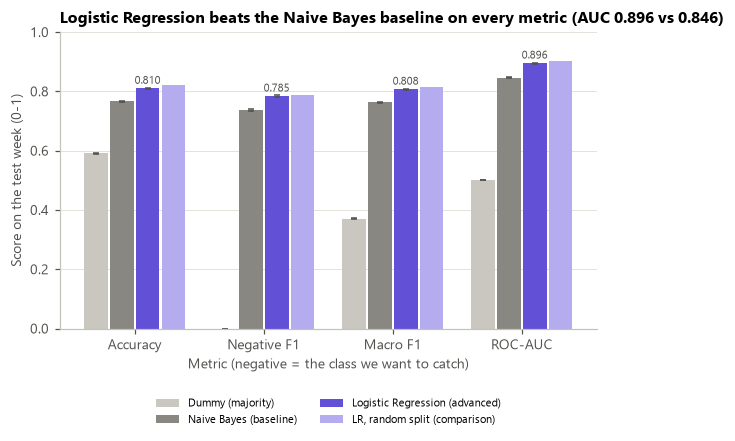

In [36]:
# Figure 5.1: model comparison on the test week (grouped columns with 95% bootstrap CIs)
MODEL_COLORS = {'Dummy (majority)': LIGHT, 'Naive Bayes (baseline)': GRAY,
                'Logistic Regression (advanced)': '#6250d6', 'LR, random split (comparison)': '#b5acf0'}
SHOW = ['Accuracy', 'Negative F1', 'Macro F1', 'ROC-AUC']
fig, ax = plt.subplots(figsize=(6.3, 3.5))
w = 0.2
xs = np.arange(len(SHOW))
for j, name in enumerate(MODELS + ['LR, random split (comparison)']):
    if name in MODELS:
        sub = metrics_long[metrics_long['Model'] == name].set_index('Metric').loc[SHOW]
        vals, err = sub['Value'], [sub['Value'] - sub['CI low'], sub['CI high'] - sub['Value']]
    else:
        vals, err = pd.Series([rand_scores[m] for m in SHOW], index=SHOW), None
    ax.bar(xs + (j - 1.5) * w, vals, width=w * 0.92, color=MODEL_COLORS[name], label=name, zorder=2,
           yerr=err, capsize=2, error_kw=dict(lw=0.8, ecolor=INK))
    if name == 'Logistic Regression (advanced)':
        for x, v in zip(xs, vals):
            ax.text(x + (j - 1.5) * w, v + 0.015, f'{v:.3f}', ha='center', fontsize=7, color=INK)
ax.set_xticks(xs, SHOW)
ax.set_ylabel('Score on the test week (0-1)')
ax.set_xlabel('Metric (negative = the class we want to catch)')
ax.set_ylim(0, 1.0)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncols=2, fontsize=7.5)
lr_auc = metrics_tbl.loc['Logistic Regression (advanced)', 'ROC-AUC']
nb_auc = metrics_tbl.loc['Naive Bayes (baseline)', 'ROC-AUC']
ax.set_title(f'Logistic Regression beats the Naive Bayes baseline on every metric (AUC {lr_auc:.3f} vs {nb_auc:.3f})')
save_fig(fig, 'fig5_1_model_comparison')

**Reading Figure 5.1.** Logistic Regression is ahead of Naive Bayes on all four metrics and the 95% bootstrap intervals do not overlap. The light bar is the random-split comparison: about one point higher, the optimism that a random split would have hidden.

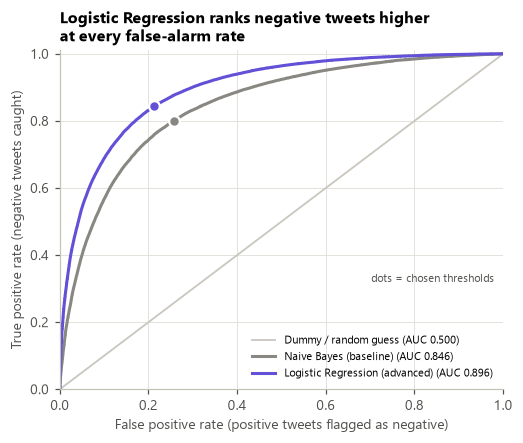

In [37]:
# Figure 5.2: ROC curves (line chart)
fig, ax = plt.subplots(figsize=(5.2, 4.0))
ax.plot([0, 1], [0, 1], color=LIGHT, lw=1.2, label='Dummy / random guess (AUC 0.500)')
for name in MODELS[1:]:
    fpr, tpr, _ = roc_curve(y_te, p_te[name])
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], lw=2, label=f"{name} (AUC {metrics_tbl.loc[name, 'ROC-AUC']:.3f})")
    pred = p_te[name] >= THR[name]
    ax.plot(((pred == 1) & (y_te == 0)).sum() / (y_te == 0).sum(), ((pred == 1) & (y_te == 1)).sum() / (y_te == 1).sum(),
            'o', color=MODEL_COLORS[name], ms=7, mec='white', mew=1.5)
ax.set_xlabel('False positive rate (positive tweets flagged as negative)')
ax.set_ylabel('True positive rate (negative tweets caught)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.legend(loc='lower right', fontsize=7.5)
ax.text(0.98, 0.32, 'dots = chosen thresholds', ha='right', fontsize=7.5, color=INK)
ax.set_title('Logistic Regression ranks negative tweets higher\nat every false-alarm rate')
save_fig(fig, 'fig5_2_roc_curves')

**Reading Figure 5.2.** The LR curve lies above the NB curve everywhere, so at whatever false-alarm rate the team accepts, LR catches more negative tweets. The dots mark the thresholds chosen on the validation week (0.44 for LR, 0.37 for NB).

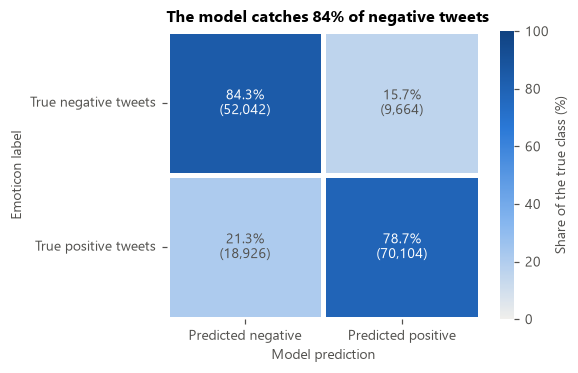

In [38]:
# Figure 5.3: confusion matrix of the chosen model (heatmap, row-normalised)
cm = confusion_matrix(y_te, pred_lr, labels=[1, 0])
cm_pct = cm / cm.sum(axis=1, keepdims=True)
keep('cm_neg_caught', cm_pct[0, 0]); keep('cm_pos_flagged', cm_pct[1, 0])
fig, ax = plt.subplots(figsize=(4.6, 3.4))
seq = mpl.colors.LinearSegmentedColormap.from_list('seq', ['#f0efec', '#86b6ef', '#2a78d6', '#104281'])
sns.heatmap(cm_pct * 100, annot=False, cmap=seq, vmin=0, vmax=100, linewidths=2, linecolor='white', ax=ax,
            cbar_kws={'label': 'Share of the true class (%)'})
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, f'{cm_pct[i, j]:.1%}\n({cm[i, j]:,})', ha='center', va='center', fontsize=9,
                color='white' if cm_pct[i, j] > 0.5 else INK)
ax.set_xticklabels(['Predicted negative', 'Predicted positive'])
ax.set_yticklabels(['True negative tweets', 'True positive tweets'], rotation=0)
ax.set_xlabel('Model prediction'); ax.set_ylabel('Emoticon label')
ax.grid(False)
ax.set_title(f'The model catches {cm_pct[0, 0]:.0%} of negative tweets')
save_fig(fig, 'fig5_3_confusion_matrix')

**Reading Figure 5.3.** The model catches 84.3% of negative tweets and wrongly flags 21.3% of positive ones. We accept more false alarms than misses on purpose: a missed complaint costs the brand more than a second look at a harmless tweet.

### 9.6 Interpreting the model

A model the marketing team cannot read will not be trusted. We explain it at two levels:

* **Globally**, through the logistic-regression coefficients. Each coefficient is the change in the log-odds of "negative" for one unit of TF-IDF weight of a term, holding the other terms fixed, so large positive values push a tweet towards *negative* and large negative values towards *positive* (the same reading as a regression slope in Chapter 7).
* **Locally**, for one tweet at a time: because the model is linear, the predicted log-odds is exactly the intercept plus the sum of *coefficient x feature value* over the terms in the tweet. Showing these contributions as a waterfall is the linear version of a SHAP explanation (Lundberg & Lee, 2017), measured from an empty tweet rather than from the average tweet.

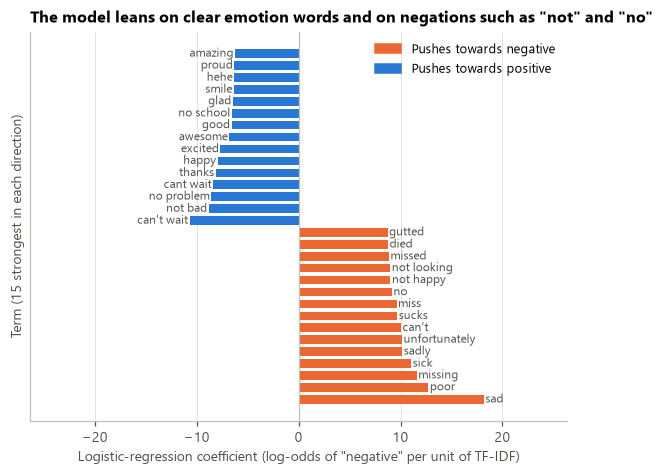

In [39]:
# Figure 5.4: global interpretation - the 15 strongest coefficients in each direction
coef = pd.Series(lr.coef_[0], index=tv_lr.get_feature_names_out())
top_n, top_p = coef.nlargest(15), coef.nsmallest(15)
keep('coef_top_neg', ', '.join(top_n.index[:8])); keep('coef_top_pos', ', '.join(top_p.index[:8]))
cp = pd.concat([top_p.iloc[::-1], top_n.iloc[::-1]]).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.3, 4.6))
ax.barh(np.arange(len(cp)), cp.values, color=[NEG if v > 0 else POS for v in cp.values], height=0.72, zorder=2)
for y, (term, v) in enumerate(cp.items()):
    ax.text(v + (0.15 if v > 0 else -0.15), y, term, va='center', ha='left' if v > 0 else 'right', fontsize=8, color=INK)
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_yticks([])
lim = np.abs(cp).max() * 1.45
ax.set_xlim(-lim, lim)
ax.set_xlabel('Logistic-regression coefficient (log-odds of "negative" per unit of TF-IDF)')
ax.set_ylabel('Term (15 strongest in each direction)')
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=NEG, label='Pushes towards negative'), Patch(color=POS, label='Pushes towards positive')],
          loc='upper right')
ax.set_title('The model leans on clear emotion words and on negations such as "not" and "no"')
save_fig(fig, 'fig5_4_lr_coefficients')

**Reading Figure 5.4.** The strongest negative terms are clear emotion words (*sad*, *poor*, *missing*, *sick*, *sucks*) and negated phrases (*not happy*). Word pairs matter: *not bad* and *no problem* push towards positive, the opposite of *not* and *no* on their own, and *can't wait* is the most positive term in the model.

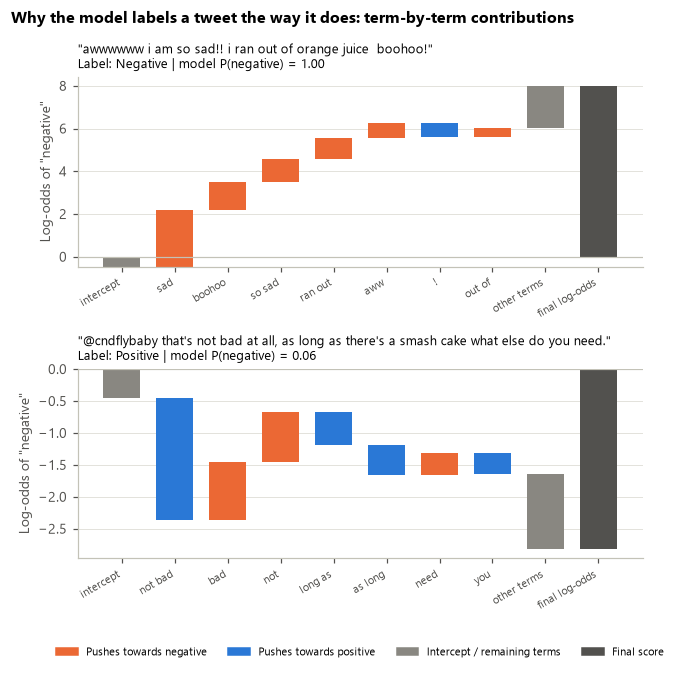

In [40]:
# Figure 5.5: local interpretation - waterfall of term contributions for two F&B test tweets
vocab_lr = tv_lr.get_feature_names_out()
def contributions(text):
    x = tv_lr.transform([text])
    idx = x.indices
    contrib = pd.Series(x.data * lr.coef_[0][idx], index=vocab_lr[idx]).sort_values(key=np.abs, ascending=False)
    return contrib, lr.intercept_[0]

ft = test[test['is_fnb']].assign(p=p_lr[fnb_mask])
cands1 = ft[(ft['neg'] == 1) & (ft['p'] > 0.85) & ft['n_words'].between(10, 18) &
            ft['text_norm'].str.contains(r'\b(?:closed|ran out|sold out|line|wait|waited|order)\b', regex=True)]
cands2 = ft[(ft['neg'] == 0) & ft['n_words'].between(8, 18) &
            ft['text_norm'].str.contains(r"\b(?:not bad|no complaints|can't complain|not too bad)\b", regex=True)]
examples = [cands1.sample(1, random_state=SEED).iloc[0], (cands2 if len(cands2) else ft[ft['neg'] == 0]).sample(1, random_state=SEED).iloc[0]]

fig, axes = plt.subplots(2, 1, figsize=(6.3, 6.4))
for ax, ex in zip(axes, examples):
    contrib, b0 = contributions(ex['text_norm'])
    show = contrib.head(7)
    rest = contrib.iloc[7:].sum()
    steps = [('intercept', b0)] + list(show.items()) + ([('other terms', rest)] if len(contrib) > 7 else [])
    cum = 0.0
    for i, (lab, v) in enumerate(steps):
        ax.bar(i, v, bottom=cum, color=GRAY if lab in ('intercept', 'other terms') else (NEG if v > 0 else POS),
               width=0.7, zorder=2)
        cum += v
    total = cum
    ax.bar(len(steps), total, color=INK, width=0.7, zorder=2)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ['final log-odds'], rotation=30, ha='right', fontsize=7.5)
    ax.set_ylabel('Log-odds of "negative"')
    prob = 1 / (1 + np.exp(-total))
    txt = ex['text_disp'] if len(ex['text_disp']) < 95 else ex['text_disp'][:92] + '...'
    ax.set_title(f'"{txt}"\nLabel: {ex["label"]} | model P(negative) = {prob:.2f}', fontsize=8.5, fontweight='normal')
    ax.grid(axis='x', visible=False)
axes[1].legend(handles=[Patch(color=NEG, label='Pushes towards negative'), Patch(color=POS, label='Pushes towards positive'),
                        Patch(color=GRAY, label='Intercept / remaining terms'), Patch(color=INK, label='Final score')],
               loc='upper center', bbox_to_anchor=(0.5, -0.42), ncols=4, fontsize=7)
fig.suptitle('Why the model labels a tweet the way it does: term-by-term contributions', fontsize=10.5,
             fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig5_5_local_explanation_waterfall')
_ = keep('example1_text', examples[0]['text_disp']), keep('example2_text', examples[1]['text_disp'])

**Reading Figure 5.5.** In the first tweet, *sad*, *boohoo*, *so sad* and *ran out* push the score to a near-certain negative. In the second, the pair *not bad* outweighs *bad* and *not* on their own, something a single-word model cannot do. This is the explanation a community manager would see when a tweet is flagged.

In [41]:
# Error analysis: the most confident mistakes on F&B test tweets
err = ft.assign(pred=(ft['p'] >= thr_lr).astype(int))
fp = err[(err['pred'] == 1) & (err['neg'] == 0)].nlargest(6, 'p')
fn = err[(err['pred'] == 0) & (err['neg'] == 1)].nsmallest(6, 'p')
errors_tbl = pd.concat([fp.assign(error='False alarm'), fn.assign(error='Missed negative')])[['error', 'label', 'p', 'text_disp']]
errors_tbl.columns = ['Error type', 'Emoticon label', 'P(negative)', 'Tweet']
errors_tbl.style.format({'P(negative)': '{:.2f}'}).hide(axis='index')

Error type,Emoticon label,P(negative),Tweet
False alarm,Positive,0.99,Tired....hungry....still dreading orchestra
False alarm,Positive,0.99,@irwinfelddesign OH NO so sorry to hear your stomach is not well...tea with a little lemon & honey helps me
False alarm,Positive,0.99,"ah dam., I am so sad Mike drank too much and fell asleep already! I was hoping for some hot sex. ;) maybe in the AM now i guess! ;)"
False alarm,Positive,0.99,cause i'm happy but disappointed my car is messing up.....my poor baby. now i'm hungry with no way to get food. What's in this house?????
False alarm,Positive,0.99,In work. Lunch cancelled. Boss not in. More time to prepare presentation
False alarm,Positive,0.99,my jaw hurts! volleyball torture tonight. grrr. sunburn really really hurts! but tomorrow it will be a tan. eating creamy pesto!
Missed negative,Negative,0.01,LUNCH.....finally
Missed negative,Negative,0.01,"Making quesidillas and watching runs house, eating myself happy"
Missed negative,Negative,0.02,"You got that confidence, sexiness, thickness that bomb play And I like it all, yeah. CAKE!"
Missed negative,Negative,0.02,@Sazchik With his special Shepherds Pie & Krug Champagne bless him....


**Error analysis.** Many of the most confident "mistakes" are label noise rather than model errors: "Tired....hungry....still dreading orchestra" carries a positive emoticon, and "Amazing wedding cakes is on!" a negative one. Others mix two moods in one tweet ("happy but disappointed my car is messing up"). The 96.9% agreement found in the manual review (Section 5.4) is a rough ceiling on how closely any model can match these labels.

## 10. Prescriptive analysis: what should the marketing team do next week?

**Goal:** turn the three previous layers into a decision and a short list of actions (Chapter 1: prescriptive analytics answers "What should we do? How can we improve?" by combining earlier insights and simulating scenarios).
**Method:**
1. Estimate next week's negative share with the model, correcting for its known error rates (*adjusted classify-and-count*, Forman 2008), and check the estimate against the true labels we held back.
2. Place every aspect on a priority matrix: how much of the conversation it holds, how much more negative it is, and how many negative tweets it is expected to produce next week.
3. Simulate "what if a message change reduced negativity in aspect X by *k* points?"
4. Define an alert rule for daily monitoring and back-test it.
5. Apply a decision rule written down **before** looking at the recommendation.

**Decision rule.** Rewrite the whole campaign message only if the launch week is significantly *and* practically more negative than the baseline (H4). Make *targeted* adjustments if at least one product-directed aspect is at least 5 pp more negative than the rest of the F&B conversation, with the whole 95% CI above zero. Otherwise keep the message and keep monitoring.

In [42]:
# ------------------------------------------------------------------
# 10.1 Score every F&B tweet and estimate next week's negative share
# ------------------------------------------------------------------
X_fnb = tv_lr.transform(fnb['text_norm'])
fnb['proba_neg'] = lr.predict_proba(X_fnb)[:, 1]
fnb['pred_neg'] = (fnb['proba_neg'] >= thr_lr).astype('int8')

def acc_estimate(pred, tpr, fpr):
    """Adjusted classify-and-count: correct the raw share of predicted negatives with the model's error rates."""
    q = pred.mean()
    return q, float(np.clip((q - fpr) / (tpr - fpr), 0, 1))

v_f = fnb[fnb['period'] == 'Launch week']                         # error rates measured on the validation week
tpr = ((v_f['pred_neg'] == 1) & (v_f['neg'] == 1)).sum() / (v_f['neg'] == 1).sum()
fpr = ((v_f['pred_neg'] == 1) & (v_f['neg'] == 0)).sum() / (v_f['neg'] == 0).sum()
t_f = fnb[fnb['period'] == 'Next week']
q_raw, q_adj = acc_estimate(t_f['pred_neg'], tpr, fpr)
true_next = t_f['neg'].mean()
keep('val_fnb_tpr', tpr); keep('val_fnb_fpr', fpr)
keep('next_fnb_neg_raw_cc', q_raw); keep('next_fnb_neg_adjusted', q_adj); keep('next_fnb_neg_true', true_next)
print(f'F&B tweets next week: raw share predicted negative = {q_raw:.1%}, adjusted estimate = {q_adj:.1%}, '
      f'true share (held back) = {true_next:.1%}')

F&B tweets next week: raw share predicted negative = 41.4%, adjusted estimate = 38.2%, true share (held back) = 36.8%


**Reading the estimate.** Simply counting predicted negatives would put next week's F&B negative share at 41.4%, because the threshold favours catching complaints. Correcting with the error rates measured on launch week (TPR 79.5%, FPR 17.8%) gives 38.2%, within 1.4 pp of the true 36.8%. This adjusted figure is what the team would report each day.

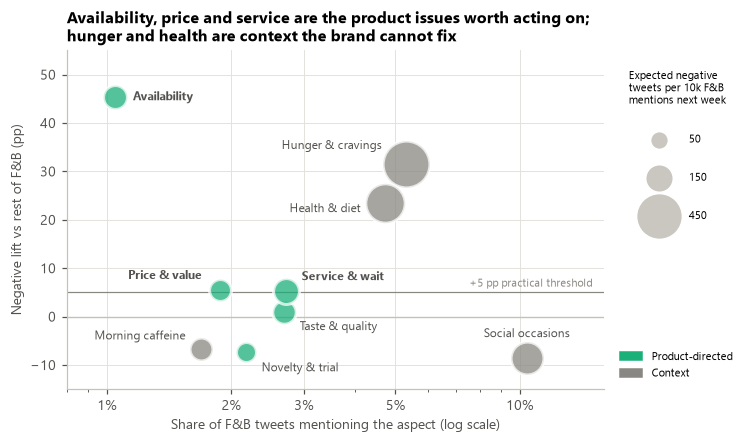

,Group,Tweets,Negative share,Lift (pp),Lift CI low,Lift CI high,Share of voice (%),Expected negative tweets per 10k F&B mentions (next week),Meets targeted-action rule
Aspect,,,,,,,,,
Taste & quality,Product-directed,2280,0.36,1.00,-1.00,2.99,2.69,102.87,False
Price & value,Product-directed,1594,0.40,5.61,3.18,8.04,1.88,87.12,True
Service & wait,Product-directed,2305,0.40,5.37,3.35,7.40,2.72,129.11,True
Availability,Product-directed,884,0.80,45.34,42.66,48.01,1.04,108.11,True
Novelty & trial,Product-directed,1843,0.28,-7.20,-9.27,-5.14,2.18,69.28,False
Hunger & cravings,Context,4494,0.65,31.47,30.04,32.91,5.31,471.29,False
Health & diet,Context,3994,0.57,23.52,21.95,25.09,4.72,327.49,False
Morning caffeine,Context,1429,0.28,-6.61,-8.97,-4.26,1.69,96.57,False
Social occasions,Context,8806,0.27,-8.62,-9.61,-7.63,10.41,221.48,False


In [43]:
# ------------------------------------------------------------------
# 10.2 Priority matrix (Figure 6.1, bubble chart)
# ------------------------------------------------------------------
prio = aspect_tbl[['Group', 'Tweets', 'Negative share', 'Lift (pp)', 'Lift CI low', 'Lift CI high']].copy()
prio['Share of voice (%)'] = 100 * prio['Tweets'] / len(fnb)
nxt = fnb[fnb['period'] == 'Next week']
prio['Expected negative tweets per 10k F&B mentions (next week)'] = [
    10_000 * (nxt[a] & (nxt['pred_neg'] == 1)).sum() / len(nxt) for a in prio.index]
prio['Meets targeted-action rule'] = ((prio['Group'] == 'Product-directed') & (prio['Lift (pp)'] >= PRACTICAL_PP)
                                      & (prio['Lift CI low'] > 0))
for a in prio.index:
    keep(f"prio_neg_per10k_{a.split(' ')[0].lower()}", prio.loc[a, 'Expected negative tweets per 10k F&B mentions (next week)'], 1)

fig, ax = plt.subplots(figsize=(6.3, 4.0))
size_col = 'Expected negative tweets per 10k F&B mentions (next week)'
smax = prio[size_col].max()
# label offsets (points) chosen so that names do not collide
OFFS = {'Price & value': (-12, 9, 'right'), 'Service & wait': (10, 9, 'left'), 'Taste & quality': (10, -10, 'left'),
        'Morning caffeine': (-10, 8, 'right'), 'Novelty & trial': (10, -11, 'left'), 'Social occasions': (0, 16, 'center'),
        'Availability': (12, 0, 'left'), 'Hunger & cravings': (-16, 12, 'right'), 'Health & diet': (-16, -4, 'right')}
for a, r in prio.iterrows():
    ax.scatter(r['Share of voice (%)'], r['Lift (pp)'], s=40 + 900 * r[size_col] / smax, color=GROUP_COLORS[r['Group']],
               alpha=0.75, edgecolor='white', linewidth=2, zorder=3)
    dx, dy, ha = OFFS[a]
    ax.annotate(a, (r['Share of voice (%)'], r['Lift (pp)']), xytext=(dx, dy), textcoords='offset points', fontsize=8,
                ha=ha, va='center', color=INK, fontweight='bold' if r['Meets targeted-action rule'] else 'normal')
ax.axhline(0, color=AXIS, lw=0.9)
ax.axhline(PRACTICAL_PP, color=GRAY, lw=0.8)
ax.text(15, PRACTICAL_PP + 1.2, '+5 pp practical threshold', ha='right', fontsize=7.5, color=GRAY)
ax.set_xscale('log')
ax.set_xticks([1, 2, 3, 5, 10], ['1%', '2%', '3%', '5%', '10%'])
ax.set_xlim(0.8, 16); ax.set_ylim(-15, 55)
ax.set_xlabel('Share of F&B tweets mentioning the aspect (log scale)')
ax.set_ylabel('Negative lift vs rest of F&B (pp)')
size_handles = [ax.scatter([], [], s=40 + 900 * v / smax, color=LIGHT, edgecolor='white', label=f'{v:.0f}')
                for v in (50, 150, 450) if v <= smax * 1.05]
leg1 = ax.legend(handles=size_handles, title='Expected negative\ntweets per 10k F&B\nmentions next week',
                 loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=7.5, title_fontsize=7.5, labelspacing=2.4, borderpad=1.2, handletextpad=1.6)
ax.add_artist(leg1)
ax.legend(handles=[Patch(color=AQUA, label='Product-directed'), Patch(color=GRAY, label='Context')],
          loc='lower left', bbox_to_anchor=(1.01, 0.0), fontsize=7.5)
ax.set_title('Availability, price and service are the product issues worth acting on;\nhunger and health are context the brand cannot fix')
save_fig(fig, 'fig6_1_priority_matrix')
prio.round(2)

**Reading Figure 6.1.** The three aspects in bold meet the targeted-action rule. Availability is a small slice of the conversation (1.0%) but by far the most negative; service and waiting (2.7%) and price (1.9%) sit about 5 pp above the rest. Hunger and health produce the most negative tweets in volume, but they describe the customer's situation, not the product, so a message cannot fix them. Social occasions, novelty and morning caffeine sit below zero: these are the moments a campaign can lean on.

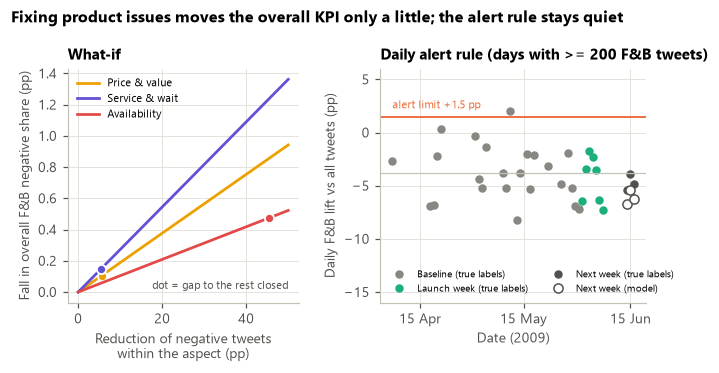

In [44]:
# ------------------------------------------------------------------
# 10.3 What-if simulation and alert rule (Figure 6.2)
# ------------------------------------------------------------------
# (a) Tweet-level what-if: if a message change turns k% of an aspect's tweets from negative to not negative,
#     the overall F&B negative share falls by k * (aspect share of voice).
ks = np.arange(0, 51, 1)
targets = prio.index[prio['Meets targeted-action rule']]
whatif = pd.DataFrame({a: ks * prio.loc[a, 'Tweets'] / len(fnb) for a in targets}, index=ks)
gap_close = {a: (prio.loc[a, 'Lift (pp)'], prio.loc[a, 'Lift (pp)'] * prio.loc[a, 'Tweets'] / len(fnb)) for a in targets}
for a, (k_gap, drop) in gap_close.items():
    keep(f"whatif_gapclose_{a.split(' ')[0].lower()}_pp", drop, 3)
keep('whatif_all_targets_pp', sum(d for _, d in gap_close.values()), 3)

# (b) Alert rule: on a day with at least 200 F&B tweets, a lift above mean + 2 SD of the baseline days triggers a review
MIN_DAY_N = 200
d_obs = daily.dropna(subset=['neg_fnb']).copy()
d_obs = d_obs[d_obs['n_fnb'] >= MIN_DAY_N]          # very small days are too noisy to act on
d_obs['period'] = np.select([d_obs.index < LAUNCH_START, d_obs.index < LAUNCH_END], ['Baseline', 'Launch week'], 'Next week')
base_days = d_obs[d_obs['period'] == 'Baseline']
ucl = base_days['lift_pp'].mean() + 2 * base_days['lift_pp'].std()
# For next week we monitor with model predictions (labels would not exist in real time)
all_next = df[df['period'] == 'Next week']
pred_all_next = (lr.predict_proba(tv_lr.transform(all_next['text_norm']))[:, 1] >= thr_lr).astype(int)
pred_daily = pd.DataFrame({'date': all_next['date'].to_numpy(), 'pred': pred_all_next}).groupby('date')['pred'].mean()
pred_fnb_daily = nxt.groupby('date')['pred_neg'].mean()
pred_lift = 100 * (pred_fnb_daily - pred_daily)
d_obs['above_ucl'] = d_obs['lift_pp'] > ucl
keep('alert_ucl_pp', ucl, 2); keep('alert_base_mean_pp', base_days['lift_pp'].mean(), 2)
keep('alert_base_sd_pp', base_days['lift_pp'].std(), 2)
keep('alert_false_alarms_baseline', int(d_obs.loc[d_obs['period'] == 'Baseline', 'above_ucl'].sum()))
keep('alert_days_baseline', int((d_obs['period'] == 'Baseline').sum()))
keep('alert_launch_alarms', int(d_obs.loc[d_obs['period'] == 'Launch week', 'above_ucl'].sum()))
keep('alert_next_alarms_pred', int((pred_lift > ucl).sum()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 3.4), gridspec_kw={'width_ratios': [1, 1.15]})
wcolors = dict(zip(targets, ['#eda100', '#6250d6', '#e34948']))
for a in targets:
    ax1.plot(ks, whatif[a], color=wcolors[a], lw=1.8, label=a)
    k_gap, drop = gap_close[a]
    if k_gap <= ks.max():
        ax1.plot(k_gap, drop, 'o', color=wcolors[a], ms=6, mec='white', mew=1.2)
ax1.set_xlabel('Reduction of negative tweets\nwithin the aspect (pp)')
ax1.set_ylabel('Fall in overall F&B negative share (pp)')
ax1.set_title('What-if', fontsize=9.5)
ax1.legend(fontsize=7, loc='upper left')
ax1.text(50, 0.02, 'dot = gap to the rest closed', ha='right', fontsize=7, color=INK)

pc = {'Baseline': GRAY, 'Launch week': AQUA, 'Next week': INK}
for per, g in d_obs.groupby('period'):
    ax2.plot(g.index, g['lift_pp'], 'o', color=pc[per], ms=4.5, label=f'{per} (true labels)')
ax2.plot(pred_lift.index, pred_lift.values, 'o', mfc='white', mec=INK, ms=6, label='Next week (model)')
ax2.axhline(ucl, color=NEG, lw=1.2)
ax2.text(d_obs.index.min(), ucl + 0.8, f'alert limit {ucl:+.1f} pp', fontsize=7.5, color=NEG)
ax2.axhline(base_days['lift_pp'].mean(), color=AXIS, lw=0.8)
ax2.set_ylabel('Daily F&B lift vs all tweets (pp)')
ax2.set_xlabel('Date (2009)')
ax2.set_xticks(pd.to_datetime(['2009-04-15', '2009-05-15', '2009-06-15']))
ax2.xaxis.set_major_formatter(mpl.dates.DateFormatter('%d %b'))
ax2.set_title(f'Daily alert rule (days with >= {MIN_DAY_N} F&B tweets)', fontsize=9.5)
ax2.legend(fontsize=6.5, loc='lower left', ncols=2)
ax2.set_ylim(-16, 6)
fig.suptitle('Fixing product issues moves the overall KPI only a little; the alert rule stays quiet',
             fontsize=10.5, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
save_fig(fig, 'fig6_2_whatif_and_alert')

**Reading Figure 6.2.** Even closing the whole gap for all three product issues would lower the overall F&B negative share by only about 0.7 pp, because these aspects are a small slice of the conversation; the benefit of acting is local (fewer unhappy customers in specific situations), not a big move in the headline KPI. The alert limit (baseline mean + 2 SD = +1.5 pp) was crossed on 1 of 23 baseline days and on none of the launch-week or next-week days, with either the true labels or the model's predictions.

In [45]:
# ------------------------------------------------------------------
# 10.4 Decision and evidence table
# ------------------------------------------------------------------
h4_sig = bool(hyp_tbl.loc['H4', 'Statistically significant'] and hyp_tbl.loc['H4', 'Practically important (|diff| >= 5 pp)'])
trigger = prio.index[prio['Meets targeted-action rule']].tolist()
decision = ('Rewrite the campaign message' if h4_sig else
            'Keep the core message, make targeted adjustments' if trigger else 'Keep the message and monitor')
_ = keep('decision', decision), keep('decision_triggers', ', '.join(trigger))
print('Decision:', decision, '| triggered by:', trigger)

# Evidence table: every recommendation quotes one number from each earlier layer
K = KEY
evidence = pd.DataFrame([
    {'Recommendation': 'R1. Keep the core campaign message (no rewrite)',
     'Descriptive': f"Launch-week F&B lift {K['lift_launch_week']:+.1f} pp vs baseline {K['lift_baseline']:+.1f} pp",
     'Diagnostic': f"H4 diff-in-diff {K['H4_diff_pp']:+.1f} pp (CI {K['H4_ci']}), not significant",
     'Predictive': f"Next-week negative share estimated {K['next_fnb_neg_adjusted']:.1%} (true {K['next_fnb_neg_true']:.1%}); 0 alert days"},
    {'Recommendation': 'R2. Add an availability message: where to find the product, restock times, apology when sold out',
     'Descriptive': f"{K['asp_share_availability']:.1%} of F&B tweets",
     'Diagnostic': f"{K['asp_neg_availability']:.1%} negative ({K['asp_lift_availability']:+.1f} pp), OR {K['OR_availability']:.1f}",
     'Predictive': f"~{K['prio_neg_per10k_availability']:.0f} negative tweets per 10k mentions expected next week"},
    {'Recommendation': 'R3. Answer service and waiting complaints, especially in the evening (order-ahead, wait-time message)',
     'Descriptive': f"{K['asp_share_service']:.1%} of F&B tweets",
     'Diagnostic': f"{K['asp_lift_service']:+.1f} pp (CI {K['H1_ci']}); evening {K['heat_service_evening']:+.1f} pp; OR {K['OR_service_wait']:.2f}",
     'Predictive': f"~{K['prio_neg_per10k_service']:.0f} negative tweets per 10k mentions next week (largest product issue)"},
    {'Recommendation': 'R4. Reframe price as value (trial offer, bundle, coupon)',
     'Descriptive': f"{K['asp_share_price']:.1%} of F&B tweets",
     'Diagnostic': f"{K['asp_lift_price']:+.1f} pp (CI {K['H2_ci']}); OR {K['OR_price_value']:.2f}",
     'Predictive': f"~{K['prio_neg_per10k_price']:.0f} negative tweets per 10k mentions next week"},
    {'Recommendation': 'R5. Build creative around trying it, sharing it and morning moments; avoid "work stress" framing',
     'Descriptive': f"Social occasions are the largest aspect ({K['asp_share_social']:.1%})",
     'Diagnostic': f"Novelty {K['asp_lift_novelty']:+.1f} pp (OR {K['OR_novelty_trial']:.2f}), social {K['asp_lift_social']:+.1f} pp; work-and-breaks topic {K['topic_lift_work']:+.1f} pp",
     'Predictive': '"can\'t wait" is the most positive term in the model'},
    {'Recommendation': 'R6. Monitor daily with the classifier and the alert rule',
     'Descriptive': f"Daily F&B lift averages {K['daily_lift_mean']:+.1f} pp",
     'Diagnostic': f"Baseline SD {K['alert_base_sd_pp']:.1f} pp gives an alert limit of {K['alert_ucl_pp']:+.1f} pp",
     'Predictive': (f"AUC {metrics_tbl.loc['Logistic Regression (advanced)', 'ROC-AUC']:.3f}, catches "
                    f"{metrics_tbl.loc['Logistic Regression (advanced)', 'Negative recall']:.0%} of negative tweets")},
])
evidence.to_csv(DIRS['art'] / 'evidence_table.csv', index=False, encoding='utf-8-sig')
evidence.style.hide(axis='index')

Decision: Keep the core message, make targeted adjustments | triggered by: ['Price & value', 'Service & wait', 'Availability']


Recommendation,Descriptive,Diagnostic,Predictive
R1. Keep the core campaign message (no rewrite),Launch-week F&B lift -5.4 pp vs baseline -5.1 pp,"H4 diff-in-diff -0.3 pp (CI -1.0 to +0.4), not significant",Next-week negative share estimated 38.2% (true 36.8%); 0 alert days
"R2. Add an availability message: where to find the product, restock times, apology when sold out",1.0% of F&B tweets,"79.6% negative (+45.3 pp), OR 7.2",~108 negative tweets per 10k mentions expected next week
"R3. Answer service and waiting complaints, especially in the evening (order-ahead, wait-time message)",2.7% of F&B tweets,+5.4 pp (CI +3.3 to +7.4); evening +10.2 pp; OR 1.11,~129 negative tweets per 10k mentions next week (largest product issue)
"R4. Reframe price as value (trial offer, bundle, coupon)",1.9% of F&B tweets,+5.6 pp (CI +3.2 to +8.0); OR 1.21,~87 negative tweets per 10k mentions next week
"R5. Build creative around trying it, sharing it and morning moments; avoid ""work stress"" framing",Social occasions are the largest aspect (10.4%),"Novelty -7.2 pp (OR 0.66), social -8.6 pp; work-and-breaks topic +13.7 pp","""can't wait"" is the most positive term in the model"
R6. Monitor daily with the classifier and the alert rule,Daily F&B lift averages -3.9 pp,Baseline SD 2.6 pp gives an alert limit of +1.5 pp,"AUC 0.896, catches 84% of negative tweets"


## Summary

| Layer | Main result |
|---|---|
| Data | 1.6 M tweets, of which 275,225 come from a negative-only tail and were removed; 1,274,034 clean tweets; 84,632 F&B tweets (dictionary precision 89.0%) |
| Descriptive | F&B tweets are 5.1 pp less negative than all tweets; launch week looks like any other week; everyday meal talk dominates and only 7.5% names a brand |
| Diagnostic | Availability (+45.3 pp), price (+5.6 pp) and service (+5.4 pp, +10.2 pp in the evening) are the negative product aspects; trial, social and morning moments are positive; the launch week did not change the lift (H4 not significant) |
| Predictive | Logistic Regression on word and word-pair TF-IDF beats Naive Bayes on the next week: AUC 0.896 vs 0.846, accuracy 81.0% vs 76.6%, McNemar gain +4.4 pp |
| Prescriptive | Keep the core message and make targeted adjustments on availability, service and price; build creative around trial and sharing; monitor daily with an alert limit of +1.5 pp |

## 11. Export for the report, slides and dashboard

Every number quoted in the report and the slides comes from `artifacts/key_numbers.json`, written here, so the three deliverables cannot drift apart. The dashboard only needs the scored F&B tweets, the daily table and the fitted model, so it starts in seconds and does not need the 239 MB raw file.

In [46]:
# ------------------------------------------------------------------
# 11.1 Data and tables
# ------------------------------------------------------------------
export_cols = (['ids', 'dt', 'date', 'user', 'text_disp', 'label', 'neg', 'proba_neg', 'pred_neg', 'period', 'category',
                'brands', 'topic', 'daypart', 'hour', 'weekday', 'n_words'] + ASPECT_ORDER)
fnb_out = fnb[export_cols].copy()
fnb_out['daypart'] = fnb_out['daypart'].astype(str)
fnb_out.to_parquet(DIRS['proc'] / 'fnb_scored.parquet', index=False)
# The dashboard can show model-based numbers too, so we also store the model's daily negative share for ALL tweets
pred_all = (lr.predict_proba(tv_lr.transform(df['text_norm']))[:, 1] >= thr_lr).astype(int)
daily['neg_all_pred'] = pd.Series(pred_all, index=df.index).groupby(df['date']).mean().reindex(daily.index)
daily.rename_axis('date').to_csv(DIRS['proc'] / 'daily_negative_share.csv')

tables = {'cleaning_log': log_df, 'period_summary': period_tbl, 'brand_stats': brand_stats, 'topics': topic_tbl,
          'aspect_stats': aspect_tbl, 'hypotheses': hyp_tbl, 'logit_odds_ratios': or_tbl, 'distinctive_words': fw,
          'aspect_daypart_lift': heat, 'split_design': split_tbl, 'tuning': tune_tbl, 'test_metrics': metrics_long,
          'test_metrics_threshold_05': metrics_05, 'robustness': robust, 'errors_fnb': errors_tbl,
          'priority_matrix': prio, 'whatif': whatif, 'validation_review_by_category': by_cat if reviewed_path.exists() else pd.DataFrame()}
for name, t in tables.items():
    t.to_csv(DIRS['art'] / f'{name}.csv', encoding='utf-8-sig')
pd.concat([coef.nlargest(30), coef.nsmallest(30)]).rename('coefficient').to_csv(DIRS['art'] / 'lr_top_coefficients.csv', encoding='utf-8-sig')

# ------------------------------------------------------------------
# 11.2 Model: one scikit-learn pipeline (TF-IDF + Logistic Regression) plus the chosen threshold
# ------------------------------------------------------------------
if hasattr(tv_lr, 'stop_words_'):
    tv_lr.stop_words_ = None                      # pruned-term list is not needed to predict and is large
pipe = Pipeline([('tfidf', tv_lr), ('clf', lr)])
joblib.dump({'pipeline': pipe, 'threshold': thr_lr, 'trained_on': 'Sentiment140, 6 Apr - 31 May 2009',
             'positive_class': 'negative sentiment (1)'}, DIRS['art'] / 'model_lr.joblib', compress=3)
joblib.dump({'vectorizer': cv_nb, 'model': nb, 'threshold': THR['Naive Bayes (baseline)']}, DIRS['art'] / 'model_nb.joblib', compress=3)

metrics_json = {'thresholds': THR, 'best_C': best_C, 'best_alpha': best_alpha,
                'test': metrics_tbl.round(4).to_dict(orient='index'), 'robustness': robust.round(4).to_dict(orient='index')}
(DIRS['art'] / 'metrics.json').write_text(json.dumps(metrics_json, indent=2, default=str), encoding='utf-8')
(DIRS['art'] / 'key_numbers.json').write_text(json.dumps(KEY, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
print(f'{len(KEY)} key numbers, {len(tables) + 1} tables, 2 models and {len(list(DIRS["fig"].glob("*.png")))} figures saved.')
print('Files:', sorted(p.name for p in DIRS['art'].iterdir())[:8], '...')

299 key numbers, 19 tables, 2 models and 20 figures saved.
Files: ['aspect_daypart_lift.csv', 'aspect_stats.csv', 'brand_stats.csv', 'cleaning_log.csv', 'distinctive_words.csv', 'errors_fnb.csv', 'evidence_table.csv', 'hypotheses.csv'] ...
